# Manuscript Figures and Tables: Morphometry (main) + Tractometry (companion)
## Epilepsy vs. FS, Focal vs. Generalized, Drug-Resistant vs. Drug-Responsive

Inputs: cortical thickness and subcortical volume z-scores from `../data/centilebrain_zscores/` (CentileBrain output from FreeSurfer 7.3.2 on all 355 cohort subjects, T1w only, no FLAIR pial refinement), node-level tractometry z-scores and the clinical metadata from `../data/`. The misspelled CentileBrain columns (`entorhil`, `supramargil`) are renamed so entorhinal and supramarginal are included in the temporal and parietal composites (missing columns raise an error). The arcuate is averaged across both hemispheres (AF_L + AF_R) like the other paired tracts. The occipital composite uses all four Desikan-Killiany occipital regions (cuneus, lateral occipital, lingual, pericalcarine).

Main figures: **four single-metric subplots per figure**, each a dot+CI plot with the **raw z-score (or asymmetry
index) on the x-axis** — not AUC. Each row is a region/tract; two dots per row, one per group, at that
group's own median with a bootstrap 95% CI, color-coded by group (with a legend — color means group
identity here, nothing else). Vertical dashed line at 0 = the normative reference (or, for the
asymmetry panel, perfect symmetry).

**Layout**: A. Morphometry composite z-score (7 regions). B. Hemispheric asymmetry index (7 regions).
C. Tractometry FA (9 tracts). D. Tractometry MD (9 tracts).

**AUC is not shown on these figures** — the discriminability/significance numbers (AUC, bootstrap CI,
pooled-family FDR q) are computed below and reported in the tables, per comparison, and painted onto the
brain maps of Figure 5.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
RNG_SEED = 42

## 1. Load Morphometry (7 lobar composites), All Group Subsets

In [2]:
base = '../data'
morph_base = '../data/centilebrain_zscores'  # FreeSurfer 7.3.2 (T1w only) -> CentileBrain z-scores
meta_path = '../data/metadata_drug_responsiveness.csv'

ct = pd.concat([pd.read_csv(f'{morph_base}/zscore_CorticalThickness_male.csv'),
                pd.read_csv(f'{morph_base}/zscore_CorticalThickness_female.csv')], ignore_index=True)
sv = pd.concat([pd.read_csv(f'{morph_base}/zscore_SubcorticalVolume_male.csv'),
                pd.read_csv(f'{morph_base}/zscore_SubcorticalVolume_female.csv')], ignore_index=True)
# CentileBrain's output misspells two Desikan-Killiany regions (entorhil, supramargil); restore the standard
# names so the lobar groupings below pick them up.
ct = ct.rename(columns=lambda c: c.replace('_entorhil_', '_entorhinal_').replace('_supramargil_', '_supramarginal_'))
both_subs = set(ct['SubjectID']) & set(sv['SubjectID'])
ct = ct[ct['SubjectID'].isin(both_subs)].copy()
sv = sv[sv['SubjectID'].isin(both_subs)].copy()
sv_zcols = [c for c in sv.columns if c not in ['SITE', 'SubjectID', 'Vendor', 'FreeSurfer_Version', 'age']]
morph = ct.merge(sv[['SubjectID'] + sv_zcols], on='SubjectID', how='inner')

meta = pd.read_csv(meta_path).rename(columns={'record_id': 'SubjectID'})
morph = morph.merge(meta[['SubjectID', 'group_1', 'group_2']], on='SubjectID', how='left')
morph = morph.drop_duplicates(subset='SubjectID', keep='first')

tract_subs = set(pd.read_csv(f'{base}/node_zscores.csv', usecols=['subject'])['subject'].unique())
morph = morph[morph['SubjectID'].isin(tract_subs)].copy()

lobar_groups = {
    'Frontal': (['caudalanteriorcingulate', 'caudalmiddlefrontal', 'lateralorbitofrontal',
                 'medialorbitofrontal', 'paracentral', 'parsopercularis', 'parsorbitalis',
                 'parstriangularis', 'precentral', 'rostralanteriorcingulate',
                 'rostralmiddlefrontal', 'superiorfrontal', 'frontalpole'], []),
    'Temporal': (['bankssts', 'entorhinal', 'fusiform', 'inferiortemporal', 'middletemporal',
                  'parahippocampal', 'superiortemporal', 'temporalpole', 'transversetemporal'],
                 ['Lhippo', 'Rhippo', 'Lamyg', 'Ramyg']),
    'Parietal': (['inferiorparietal', 'isthmuscingulate', 'postcentral', 'posteriorcingulate',
                  'precuneus', 'superiorparietal', 'supramarginal'], []),
    'Occipital': (['cuneus', 'lateraloccipital', 'lingual', 'pericalcarine'], []),  # full DK occipital lobe
    'Insula': (['insula'], []),
    'Thalamus': ([], ['Lthal', 'Rthal']),
    'Basal Ganglia': ([], ['Lcaud', 'Rcaud', 'Lput', 'Rput', 'Lpal', 'Rpal', 'Laccumb', 'Raccumb']),
}
lobe_order = list(lobar_groups.keys())
lobe_row_labels = [l.replace('Basal Ganglia', 'Basal\nGanglia') for l in lobe_order]
for lobe, (ctr, svr) in lobar_groups.items():
    cols = [f'{h}_{r}_thickavg' for r in ctr for h in ('L', 'R')] + svr
    missing = [c for c in cols if c not in morph.columns]
    assert not missing, f'{lobe}: region columns not found: {missing}'
    morph[f'z_{lobe}'] = morph[cols].mean(axis=1)

sv_pairs = {'hippo': ('Lhippo', 'Rhippo'), 'amyg': ('Lamyg', 'Ramyg'), 'thal': ('Lthal', 'Rthal'),
            'caud': ('Lcaud', 'Rcaud'), 'put': ('Lput', 'Rput'), 'pal': ('Lpal', 'Rpal'),
            'accumb': ('Laccumb', 'Raccumb')}
sv_left = {v[0] for v in sv_pairs.values()}
sv_right = {v[1] for v in sv_pairs.values()}
for lobe, (ctr, svr) in lobar_groups.items():
    l_cols = [f'L_{r}_thickavg' for r in ctr] + [c for c in svr if c in sv_left]
    r_cols = [f'R_{r}_thickavg' for r in ctr] + [c for c in svr if c in sv_right]
    missing = [c for c in l_cols + r_cols if c not in morph.columns]
    assert not missing, f'{lobe}: region columns not found: {missing}'
    morph[f'asym_{lobe}'] = (morph[l_cols].mean(axis=1) - morph[r_cols].mean(axis=1)).abs()

epi_m = morph[morph['group_2'].isin(['drug-resistant', 'drug-responsive'])].copy()
fs_m = morph[morph['group_1'] == 'pnee'].copy()
focal_m = epi_m[epi_m['group_1'] == 'focal'].copy()
generalized_m = epi_m[epi_m['group_1'] == 'generalized'].copy()
dr_m = epi_m[epi_m['group_2'] == 'drug-resistant'].copy()
ds_m = epi_m[epi_m['group_2'] == 'drug-responsive'].copy()
print(f'Morphometry -- Epilepsy: {len(epi_m)}, FS: {len(fs_m)}, Focal: {len(focal_m)}, '
      f'Generalized: {len(generalized_m)}, DR: {len(dr_m)}, DS: {len(ds_m)}')

Morphometry -- Epilepsy: 273, FS: 32, Focal: 203, Generalized: 37, DR: 97, DS: 176


## 2. Load Tractometry (9 bilateral tracts x 2 metrics), All Group Subsets

In [3]:
raw = pd.read_csv(f'{base}/node_zscores.csv')
clin = raw[(raw['cohort'] == 'Clinical') & (raw['scalar'].isin(['dti_fa', 'dti_md']))].copy()
clin = clin[clin['subject'].isin(set(morph['SubjectID']))]
clin['feature'] = clin['tract'] + '_' + clin['scalar']
wide = clin.pivot_table(index='subject', columns='feature', values='z_score').reset_index()
wide = wide.merge(meta[['SubjectID', 'group_1', 'group_2']].rename(columns={'SubjectID': 'subject'}),
                   on='subject', how='left').drop_duplicates(subset='subject', keep='first')

bilateral_tracts = {
    'Cingulum': ['C_L', 'C_R'], 'Fornix': ['F_L', 'F_R'], 'Uncinate': ['UF_L', 'UF_R'],
    'Arcuate': ['AF_L', 'AF_R'], 'IFOF': ['IFOF_L', 'IFOF_R'],
    'CC Forceps Major': ['CC_ForcepsMajor'], 'CC Forceps Minor': ['CC_ForcepsMinor'], 'CC Mid': ['CCMid'],
    'CST': ['CST_L', 'CST_R'],
}
tract_order = ['Cingulum', 'Fornix', 'Uncinate', 'Arcuate', 'IFOF',
               'CC Forceps Major', 'CC Forceps Minor', 'CC Mid', 'CST']
tract_row_labels = ['Cingulum', 'Fornix', 'Uncinate', 'Arcuate', 'IFOF',
                     'CC Forceps\nMajor', 'CC Forceps\nMinor', 'CC Mid', 'CST']

for name, tracts in bilateral_tracts.items():
    for scalar in ['dti_fa', 'dti_md']:
        col = f'zb_{name}_{scalar}'.replace(' ', '_')
        fc = [f'{t}_{scalar}' for t in tracts]
        missing = [c for c in fc if c not in wide.columns]
        assert not missing, f'{name}: tract columns not found: {missing}'
        wide[col] = wide[fc].mean(axis=1)

epi_t = wide[wide['group_2'].isin(['drug-resistant', 'drug-responsive'])].copy()
fs_t = wide[wide['group_1'] == 'pnee'].copy()
focal_t = epi_t[epi_t['group_1'] == 'focal'].copy()
generalized_t = epi_t[epi_t['group_1'] == 'generalized'].copy()
dr_t = epi_t[epi_t['group_2'] == 'drug-resistant'].copy()
ds_t = epi_t[epi_t['group_2'] == 'drug-responsive'].copy()

morph_groups = {'Epilepsy': epi_m, 'FS': fs_m, 'Focal': focal_m, 'Generalized': generalized_m,
                 'DR': dr_m, 'DS': ds_m}
tract_groups = {'Epilepsy': epi_t, 'FS': fs_t, 'Focal': focal_t, 'Generalized': generalized_t,
                 'DR': dr_t, 'DS': ds_t}
print(f'Tractometry -- Epilepsy: {len(epi_t)}, FS: {len(fs_t)}, Focal: {len(focal_t)}, '
      f'Generalized: {len(generalized_t)}, DR: {len(dr_t)}, DS: {len(ds_t)}')

Tractometry -- Epilepsy: 273, FS: 32, Focal: 203, Generalized: 37, DR: 97, DS: 176


## 3. AUC + Bootstrap CI (Mann-Whitney), Pooled-FDR Family per Series

`AUC = P(group_a > group_b)` via the Mann-Whitney U statistic; 95% CI from 5000 within-group bootstrap
resamples. FDR pooled across the 7 regions (morphometry, per series) or all 18 tract x metric series
(tractometry).

In [4]:
morph_cols = [f'z_{l}' for l in lobe_order]
morph_asym_cols = [f'asym_{l}' for l in lobe_order]
tract_cols_fa = [f'zb_{t}_dti_fa'.replace(' ', '_') for t in tract_order]
tract_cols_md = [f'zb_{t}_dti_md'.replace(' ', '_') for t in tract_order]
tract_cols_all18 = tract_cols_fa + tract_cols_md

def mwu_auc(a, b):
    U, p = mannwhitneyu(a, b, alternative='two-sided')
    return U / (len(a) * len(b)), p

def bootstrap_auc_ci(a, b, n_boot=5000, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    n_a, n_b = len(a), len(b)
    aucs = np.empty(n_boot)
    for k in range(n_boot):
        bs_a = rng.choice(a, size=n_a, replace=True)
        bs_b = rng.choice(b, size=n_b, replace=True)
        U, _ = mannwhitneyu(bs_a, bs_b, alternative='two-sided')
        aucs[k] = U / (n_a * n_b)
    return np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)

def auc_family(group_a_df, group_b_df, cols):
    aucs, ci_los, ci_his, ps = [], [], [], []
    for col in cols:
        a = group_a_df[col].dropna().values
        b = group_b_df[col].dropna().values
        auc, p = mwu_auc(a, b)
        lo, hi = bootstrap_auc_ci(a, b)
        aucs.append(auc); ci_los.append(lo); ci_his.append(hi); ps.append(p)
    q = multipletests(ps, method='fdr_bh')[1]
    return {'auc': np.array(aucs), 'ci_lo': np.array(ci_los), 'ci_hi': np.array(ci_his), 'p': np.array(ps), 'q': np.array(q)}

def tract_auc_family(group_a_df, group_b_df):
    fa = auc_family(group_a_df, group_b_df, tract_cols_fa)
    md_ = auc_family(group_a_df, group_b_df, tract_cols_md)
    # FDR pooled across all 18 (recompute q jointly rather than per-metric)
    all_p = []
    for col in tract_cols_all18:
        a = group_a_df[col].dropna().values; b = group_b_df[col].dropna().values
        _, p = mwu_auc(a, b)
        all_p.append(p)
    q18 = multipletests(all_p, method='fdr_bh')[1]
    fa['q'], md_['q'] = q18[:9], q18[9:]
    return fa, md_

comparisons = [('Epilepsy', 'FS', 'Epilepsy', 'Functional Seizures'),
               ('Focal', 'Generalized', 'Focal', 'Generalized'),
               ('DR', 'DS', 'Drug-Resistant', 'Drug-Responsive')]

morph_auc_results, morph_asym_auc_results, tract_auc_results = {}, {}, {}
for ga, gb, la, lb in comparisons:
    morph_auc_results[(ga, gb)] = auc_family(morph_groups[ga], morph_groups[gb], morph_cols)
    morph_asym_auc_results[(ga, gb)] = auc_family(morph_groups[ga], morph_groups[gb], morph_asym_cols)
    tract_auc_results[(ga, gb)] = tract_auc_family(tract_groups[ga], tract_groups[gb])
    n_sig_m = int((morph_auc_results[(ga, gb)]['q'] < 0.05).sum())
    n_sig_asym = int((morph_asym_auc_results[(ga, gb)]['q'] < 0.05).sum())
    fa_r, md_r = tract_auc_results[(ga, gb)]
    n_sig_t = int((fa_r['q'] < 0.05).sum() + (md_r['q'] < 0.05).sum())
    print(f'{ga} vs {gb}: morphometry {n_sig_m}/7, asymmetry {n_sig_asym}/7, tractometry {n_sig_t}/18 FDR-significant '
          f'(AUC/CI/q available for a table; not plotted below)')

Epilepsy vs FS: morphometry 0/7, asymmetry 0/7, tractometry 0/18 FDR-significant (AUC/CI/q available for a table; not plotted below)


Focal vs Generalized: morphometry 0/7, asymmetry 0/7, tractometry 0/18 FDR-significant (AUC/CI/q available for a table; not plotted below)


DR vs DS: morphometry 0/7, asymmetry 0/7, tractometry 0/18 FDR-significant (AUC/CI/q available for a table; not plotted below)


## 3b. Per-Group Median + Bootstrap CI (the actual plot data)

Not a between-group comparison — for each group *separately*, the median z (or asymmetry index) per
region/tract, with a bootstrap 95% CI on that group's own median (5000 within-group resamples). This is
what the dot+CI plot below actually shows.

In [5]:
def bootstrap_median_ci(vals, n_boot=5000, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    n = len(vals)
    meds = np.empty(n_boot)
    for k in range(n_boot):
        meds[k] = np.median(rng.choice(vals, size=n, replace=True))
    return np.percentile(meds, 2.5), np.percentile(meds, 97.5)

def median_ci_family(group_df, cols):
    meds, ci_los, ci_his = [], [], []
    for col in cols:
        vals = group_df[col].dropna().values
        meds.append(np.median(vals))
        lo, hi = bootstrap_median_ci(vals)
        ci_los.append(lo); ci_his.append(hi)
    return {'med': np.array(meds), 'ci_lo': np.array(ci_los), 'ci_hi': np.array(ci_his)}

morph_med_by_group = {name: median_ci_family(df, morph_cols) for name, df in morph_groups.items()}
morph_asym_med_by_group = {name: median_ci_family(df, morph_asym_cols) for name, df in morph_groups.items()}
tract_fa_med_by_group = {name: median_ci_family(df, tract_cols_fa) for name, df in tract_groups.items()}
tract_md_med_by_group = {name: median_ci_family(df, tract_cols_md) for name, df in tract_groups.items()}
print('Per-group median + bootstrap CI computed for all 6 groups x 4 feature families.')

Per-group median + bootstrap CI computed for all 6 groups x 4 feature families.


## 4. Dot+CI Plot: 2x2 Grid, One Subplot per Metric

In [6]:
def draw_dot_ci(ax, res_a, res_b, row_labels, color_a, color_b, panel_label, xlabel, sig_q=None,
                 auc=None, legend_handles=None, xlim=None):
    n = len(row_labels)
    y = np.arange(n)
    offset = 0.15
    for i in range(n):
        ax.errorbar(res_a['med'][i], y[i] + offset,
                     xerr=[[res_a['med'][i] - res_a['ci_lo'][i]], [res_a['ci_hi'][i] - res_a['med'][i]]],
                     fmt='o', color=color_a, ecolor=color_a, elinewidth=1.4, capsize=3.5,
                     markersize=7, zorder=3)
        ax.errorbar(res_b['med'][i], y[i] - offset,
                     xerr=[[res_b['med'][i] - res_b['ci_lo'][i]], [res_b['ci_hi'][i] - res_b['med'][i]]],
                     fmt='o', color=color_b, ecolor=color_b, elinewidth=1.4, capsize=3.5,
                     markersize=7, zorder=3)
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(row_labels, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.tick_params(axis='x', labelsize=10)
    # Panel label style: "A.    Descriptor", bold, upper-left,
    # outside the axes.
    ax.text(-0.11, 1.03, panel_label, transform=ax.transAxes, fontsize=11, fontweight='bold',
             ha='left', va='bottom', clip_on=False)
    ax.invert_yaxis()
    # Significance + effect size, fixed column INSIDE the axes near the right edge (x in axes-fraction,
    # y in data coords) -- AUC is the actual statistic the significance test is based on (Mann-Whitney
    # U -> AUC -> p -> q), so it stays tied to what was tested rather than a separate effect size.
    # Expand the right xlim first so the annotation column sits in dedicated blank space rather than
    # overlapping the rightmost dots/whiskers.
    if xlim is not None:
        ax.set_xlim(*xlim)  # fixed range shared across figures (already includes the annotation column)
    if sig_q is not None and auc is not None:
        if xlim is None:
            xlo, xhi = ax.get_xlim()
            ax.set_xlim(xlo, xhi + 0.24 * (xhi - xlo))
        for i in range(n):
            if sig_q[i] < 0.001:
                stars = '***'
            elif sig_q[i] < 0.01:
                stars = '**'
            elif sig_q[i] < 0.05:
                stars = '*'
            else:
                continue
            folded_auc = max(auc[i], 1 - auc[i])
            ax.text(0.97, y[i], f'{stars} AUC={folded_auc:.2f}', transform=ax.get_yaxis_transform(),
                    fontsize=8.5, color='#D81B60', fontweight='bold', ha='right', va='center',
                    clip_on=False)
    if legend_handles is not None:
        ax.legend(handles=legend_handles, loc='upper right', fontsize=10.5, frameon=True,
                   framealpha=0.9, borderpad=0.2, handletextpad=0.2)


## 4b. Along-Tract Cluster Permutation (Node-Level Correction Only)

Max-cluster-mass permutation (5000
permutations, t-threshold at p=0.05), each tract x metric series gets its own within-tract null --
not further corrected across the other 17 series, matching standard along-tract-statistics practice
(e.g. AFQ-style bundle analyses). Fixed RNG seed.

In [7]:
from scipy.stats import t as t_dist

node_clin = clin.copy()  # already Clinical cohort, dti_fa/dti_md, node-level (has nodeID) -- Section 2

def build_node_matrix(tract_list, scalar, subj_order):
    sub = node_clin[(node_clin['tract'].isin(tract_list)) & (node_clin['scalar'] == scalar)]
    if len(tract_list) > 1:
        sub = sub.groupby(['subject', 'nodeID'], as_index=False)['z_score'].mean()
    pivot = sub.pivot_table(index='subject', columns='nodeID', values='z_score', aggfunc='mean')
    return pivot.reindex(subj_order).values

def compute_t(lab, mat):
    g1, g0 = mat[lab == 1], mat[lab == 0]
    se = np.sqrt(g1.var(0, ddof=1) / len(g1) + g0.var(0, ddof=1) / len(g0))
    return (g1.mean(0) - g0.mean(0)) / np.maximum(se, 1e-10)

def get_clusters(t_vals, thresh):
    clusters, i = [], 0
    while i < len(t_vals):
        if abs(t_vals[i]) >= thresh:
            j = i + 1
            while j < len(t_vals) and abs(t_vals[j]) >= thresh:
                j += 1
            clusters.append((i, j, float(t_vals[i:j].sum())))
            i = j
        else:
            i += 1
    return clusters

def run_cluster_family(ref_df, ref_label, case_df, case_label, n_perm=5000, seed=RNG_SEED):
    label_map = pd.concat([pd.Series(0, index=ref_df['subject']), pd.Series(1, index=case_df['subject'])])
    common_subjects = None
    for name, tract_list in bilateral_tracts.items():
        for scalar in ['dti_fa', 'dti_md']:
            m = build_node_matrix(tract_list, scalar, label_map.index)
            valid_rows = ~np.isnan(m).any(axis=1)
            subj_valid = set(label_map.index[valid_rows])
            common_subjects = subj_valid if common_subjects is None else (common_subjects & subj_valid)
    common_subjects = sorted(common_subjects)
    labels = label_map.loc[common_subjects].values.astype(int)

    matrices = {}
    for name, tract_list in bilateral_tracts.items():
        for scalar in ['dti_fa', 'dti_md']:
            matrices[(name, scalar)] = build_node_matrix(tract_list, scalar, common_subjects)

    n_subj = len(common_subjects)
    t_thresh = t_dist.ppf(1 - 0.05 / 2, df=n_subj - 2)
    rng = np.random.default_rng(seed)

    rows = []
    for (name, scalar), mat in matrices.items():
        obs_t = compute_t(labels, mat)
        obs_clusters = get_clusters(obs_t, t_thresh)
        if not obs_clusters:
            continue
        null_within = np.zeros(n_perm)
        for k in range(n_perm):
            perm_t = compute_t(rng.permutation(labels), mat)
            cl = get_clusters(perm_t, t_thresh)
            null_within[k] = max((abs(c[2]) for c in cl), default=0.0)
        for start, end, mass in obs_clusters:
            p_within = float((null_within >= abs(mass)).mean())
            rows.append({'tract': name, 'metric': ('FA' if scalar == 'dti_fa' else 'MD'),
                         'nodes': f'{start}-{end - 1}', 'n_nodes': end - start,
                         'direction': f'{case_label} > {ref_label}' if mass > 0 else f'{ref_label} > {case_label}',
                         'cluster_mass': mass, 'p_within_tract': p_within})
    return pd.DataFrame(rows).sort_values('p_within_tract').reset_index(drop=True) if rows else pd.DataFrame(rows)

cluster_tables = {
    ('Epilepsy', 'FS'): run_cluster_family(tract_groups['FS'], 'FS', tract_groups['Epilepsy'], 'Epilepsy'),
    ('Focal', 'Generalized'): run_cluster_family(tract_groups['Generalized'], 'Generalized', tract_groups['Focal'], 'Focal'),
    ('DR', 'DS'): run_cluster_family(tract_groups['DS'], 'Drug-responsive', tract_groups['DR'], 'Drug-resistant'),
}
for key, tbl in cluster_tables.items():
    n_sig = int((tbl['p_within_tract'] < 0.05).sum()) if len(tbl) else 0
    print(f'{key}: {len(tbl)} clusters detected, {n_sig} significant (node-level corrected)')

('Epilepsy', 'FS'): 18 clusters detected, 0 significant (node-level corrected)
('Focal', 'Generalized'): 28 clusters detected, 5 significant (node-level corrected)
('DR', 'DS'): 21 clusters detected, 2 significant (node-level corrected)


## 4c. Along-Tract Panel + Combined Figure Builder

Attaches the along-tract cluster results to each comparison's own figure (Panel E, below the 2x2
dot+CI grid), rather than a separate figure -- keeps each figure self-contained per the manuscript's
part-by-part (Epilepsy vs. FS / Focal vs. Generalized / DR vs. DS) structure. Comparisons with
significant clusters get one small-multiple subplot per cluster; comparisons with none get a compact
note panel instead of empty plots.

In [8]:
scalar_key_map = {'FA': 'dti_fa', 'MD': 'dti_md'}
tract_full_names = {
    'Cingulum': 'Cingulum', 'Fornix': 'Fornix', 'Uncinate': 'Uncinate Fasciculus',
    'Arcuate': 'Arcuate Fasciculus', 'IFOF': 'Inferior Fronto-Occipital Fasciculus',
    'CC Forceps Major': 'Corpus Callosum Forceps Major', 'CC Forceps Minor': 'Corpus Callosum Forceps Minor',
    'CC Mid': 'Corpus Callosum Body', 'CST': 'Corticospinal Tract',
}

def get_node_matrix_for_group(tract_list, scalar, subject_ids):
    sub = node_clin[(node_clin['tract'].isin(tract_list)) & (node_clin['scalar'] == scalar) &
                     (node_clin['subject'].isin(subject_ids))]
    if len(tract_list) > 1:
        sub = sub.groupby(['subject', 'nodeID'], as_index=False)['z_score'].mean()
    pivot = sub.pivot_table(index='subject', columns='nodeID', values='z_score', aggfunc='mean')
    pivot = pivot.reindex(columns=range(100))
    return pivot.values

def draw_along_tract_panel(ax, mat_a, mat_b, color_a, color_b, label_a, label_b,
                            tract_label, metric_label, panel_label, cluster_rows=None, show_legend=False):
    x = np.arange(mat_a.shape[1])
    mean_a, mean_b = np.nanmean(mat_a, axis=0), np.nanmean(mat_b, axis=0)
    se_a = np.nanstd(mat_a, axis=0) / np.sqrt((~np.isnan(mat_a)).sum(0))
    se_b = np.nanstd(mat_b, axis=0) / np.sqrt((~np.isnan(mat_b)).sum(0))
    cluster_rows = cluster_rows or []

    ax.plot(x, mean_a, color=color_a, linewidth=1.8, label=label_a, zorder=3)
    ax.fill_between(x, mean_a - se_a, mean_a + se_a, color=color_a, alpha=0.2, linewidth=0)
    ax.plot(x, mean_b, color=color_b, linewidth=1.8, label=label_b, zorder=3)
    ax.fill_between(x, mean_b - se_b, mean_b + se_b, color=color_b, alpha=0.2, linewidth=0)
    ax.axhline(0, color='black', linewidth=0.8, alpha=0.4, linestyle='--')

    ymin = min(np.nanmin(mean_a - se_a), np.nanmin(mean_b - se_b))
    ymax = max(np.nanmax(mean_a + se_a), np.nanmax(mean_b + se_b))
    pad = 0.14 * (ymax - ymin)
    for cluster_row in cluster_rows:
        start, end = [int(v) for v in cluster_row['nodes'].split('-')]
        ax.axvspan(start, end + 1, color='gold', alpha=0.35, zorder=0)
        ax.text((start + end + 1) / 2, ymax + 0.02 * (ymax - ymin), f"p={cluster_row['p_within_tract']:.3f}",
                 ha='center', va='bottom', fontsize=8, color='darkgoldenrod')

    ax.set_ylim(ymin - 0.05 * (ymax - ymin), ymax + pad)
    ax.set_xlabel('Node (0 \u2192 99)')
    ax.set_ylabel('Z-Score')
    ax.set_xlim(0, 99)

    display_name = tract_full_names.get(tract_label, tract_label)
    ax.text(-0.11, 1.03, f'{panel_label}.    {display_name} ({metric_label})', transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='bottom', ha='left', clip_on=False)
    if show_legend:
        ax.legend(fontsize=9, loc='upper left')

COLOR_A, COLOR_B = '#1E88E5', '#E53935'

def sig_cluster_groups(key):
    # Group multiple significant clusters within the same tract x metric series into one subplot
    # (e.g. two separate IFOF MD clusters get one IFOF MD panel with two shaded regions), rather than
    # repeating the same line plot once per cluster.
    cluster_tbl = cluster_tables[key]
    if not len(cluster_tbl):
        return []
    sig = cluster_tbl[cluster_tbl['p_within_tract'] < 0.05].reset_index(drop=True)
    return list(sig.groupby(['tract', 'metric'], sort=False)) if len(sig) else []

# One asymmetry x-range for all three figures so Panel B is directly comparable across them: span the largest
# upper CI over every group, with the same 5% margins and 24% annotation space draw_dot_ci adds by default.
_asym_hi = max(r['ci_hi'].max() for r in morph_asym_med_by_group.values())
ASYM_XLIM = (-0.05 * _asym_hi, 1.05 * _asym_hi + 0.24 * 1.10 * _asym_hi)

def draw_forest_grid(ax00, ax01, ax10, ax11, group_a, group_b, label_a, label_b):
    key = (group_a, group_b)
    fa_res, md_res = tract_auc_results[key]
    legend_handles = [mlines.Line2D([], [], color=COLOR_A, marker='o', linestyle='None', markersize=8, label=label_a),
                       mlines.Line2D([], [], color=COLOR_B, marker='o', linestyle='None', markersize=8, label=label_b)]
    draw_dot_ci(ax00, morph_med_by_group[group_a], morph_med_by_group[group_b], lobe_row_labels,
                COLOR_A, COLOR_B, 'A.    Lobar Composite Z-Scores', 'Z-Score',
                sig_q=morph_auc_results[key]['q'], auc=morph_auc_results[key]['auc'],
                legend_handles=legend_handles)
    draw_dot_ci(ax01, morph_asym_med_by_group[group_a], morph_asym_med_by_group[group_b], lobe_row_labels,
                COLOR_A, COLOR_B, 'B.    Hemispheric Asymmetry Index', r'Asymmetry $|z_{left} - z_{right}|$',
                sig_q=morph_asym_auc_results[key]['q'], auc=morph_asym_auc_results[key]['auc'], xlim=ASYM_XLIM)
    draw_dot_ci(ax10, tract_fa_med_by_group[group_a], tract_fa_med_by_group[group_b], tract_row_labels,
                COLOR_A, COLOR_B, 'C.    Tractometry, FA', 'Z-Score', sig_q=fa_res['q'], auc=fa_res['auc'])
    draw_dot_ci(ax11, tract_md_med_by_group[group_a], tract_md_med_by_group[group_b], tract_row_labels,
                COLOR_A, COLOR_B, 'D.    Tractometry, MD', 'Z-Score', sig_q=md_res['q'], auc=md_res['auc'])

def draw_along_tract_grid(fig, gs, sig_groups, group_a, group_b, label_a, label_b, n_cols, first_label='E'):
    subj_a = set(tract_groups[group_a]['subject'])
    subj_b = set(tract_groups[group_b]['subject'])
    for i, ((tract_name, metric_name), rows) in enumerate(sig_groups):
        r, c = divmod(i, n_cols)
        ax = fig.add_subplot(gs[r, c])
        tract_list = bilateral_tracts[tract_name]
        scalar = scalar_key_map[metric_name]
        mat_a = get_node_matrix_for_group(tract_list, scalar, subj_a)
        mat_b = get_node_matrix_for_group(tract_list, scalar, subj_b)
        cluster_rows_list = [rr for _, rr in rows.iterrows()]
        draw_along_tract_panel(ax, mat_a, mat_b, COLOR_A, COLOR_B, label_a, label_b,
                                tract_name, metric_name, chr(ord(first_label) + i),
                                cluster_rows=cluster_rows_list, show_legend=False)
    # One legend below the grid rather than inside a panel, where it can cover a cluster's p-value label.
    fig.legend(handles=[mlines.Line2D([], [], color=COLOR_A, linewidth=2, label=label_a.replace('\n', ' ')),
                        mlines.Line2D([], [], color=COLOR_B, linewidth=2, label=label_b.replace('\n', ' '))],
               loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=10)

def build_full_comparison_figure(group_a, group_b, label_a, label_b, save_name):
    sig_groups = sig_cluster_groups((group_a, group_b))
    n_sig = len(sig_groups)

    if n_sig == 0:
        # No along-tract statement embedded in the figure itself when there's nothing to show --
        # plain 2x2 grid only, following the convention
        # of leaving interpretation to the figure caption rather than in-figure text.
        fig, axes = plt.subplots(2, 2, figsize=(11, 8.6),
                                  gridspec_kw={'height_ratios': [len(lobe_order), len(tract_row_labels)],
                                               'wspace': 0.35, 'hspace': 0.32})
        ax00, ax01 = axes[0, 0], axes[0, 1]
        ax10, ax11 = axes[1, 0], axes[1, 1]
    else:
        n_cols = 2
        tract_rows = int(np.ceil(n_sig / n_cols))
        tract_height = 3.2 * tract_rows

        fig = plt.figure(figsize=(12, 8.6 + tract_height))
        outer = fig.add_gridspec(2, 1, height_ratios=[8.6, tract_height], hspace=0.155)

        top = outer[0].subgridspec(2, 2, height_ratios=[len(lobe_order), len(tract_row_labels)],
                                    wspace=0.3, hspace=0.32)
        ax00, ax01 = fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])
        ax10, ax11 = fig.add_subplot(top[1, 0]), fig.add_subplot(top[1, 1])

    draw_forest_grid(ax00, ax01, ax10, ax11, group_a, group_b, label_a, label_b)

    if n_sig > 0:
        bottom = outer[1].subgridspec(tract_rows, n_cols, wspace=0.28, hspace=0.4)
        draw_along_tract_grid(fig, bottom, sig_groups, group_a, group_b, label_a, label_b, n_cols)

    plt.savefig(f'../outputs/{save_name}', bbox_inches='tight', dpi=300)
    plt.savefig(f'../outputs/{save_name.replace(".pdf", ".png")}', bbox_inches='tight', dpi=300)
    plt.show()

## Figure 2: Epilepsy vs. Functional Seizures

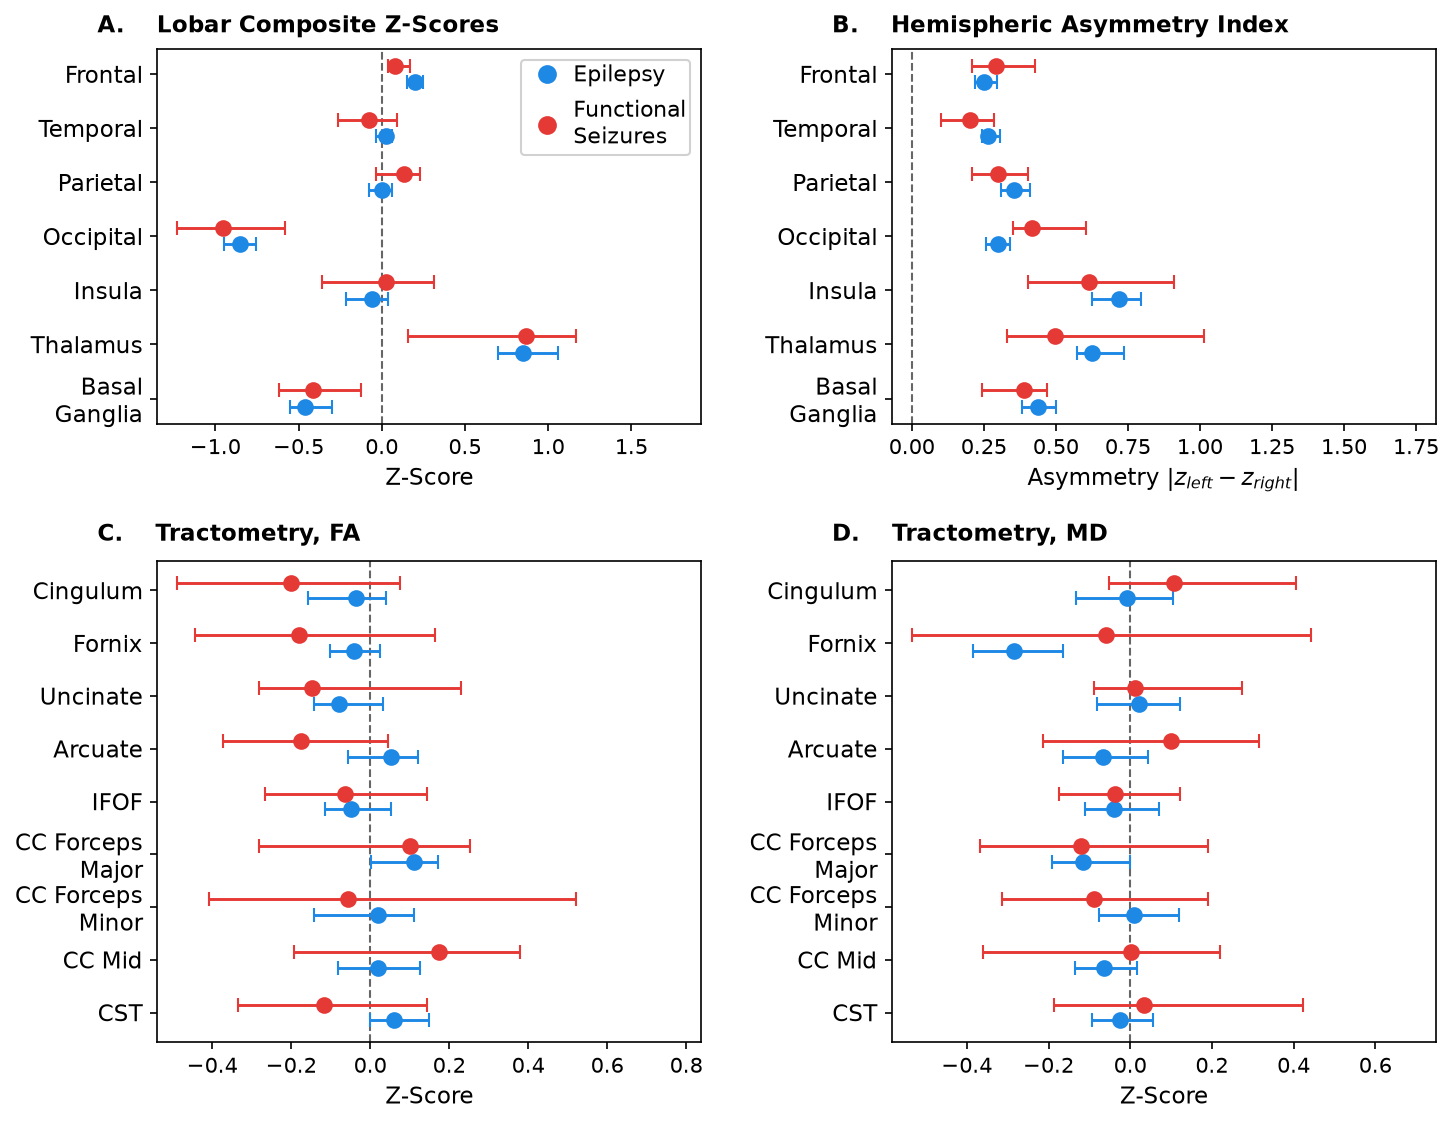

In [9]:
build_full_comparison_figure('Epilepsy', 'FS', 'Epilepsy', 'Functional\nSeizures',
                              'figure2_dotplot.pdf')

## Figure 3: Focal vs. Generalized Epilepsy

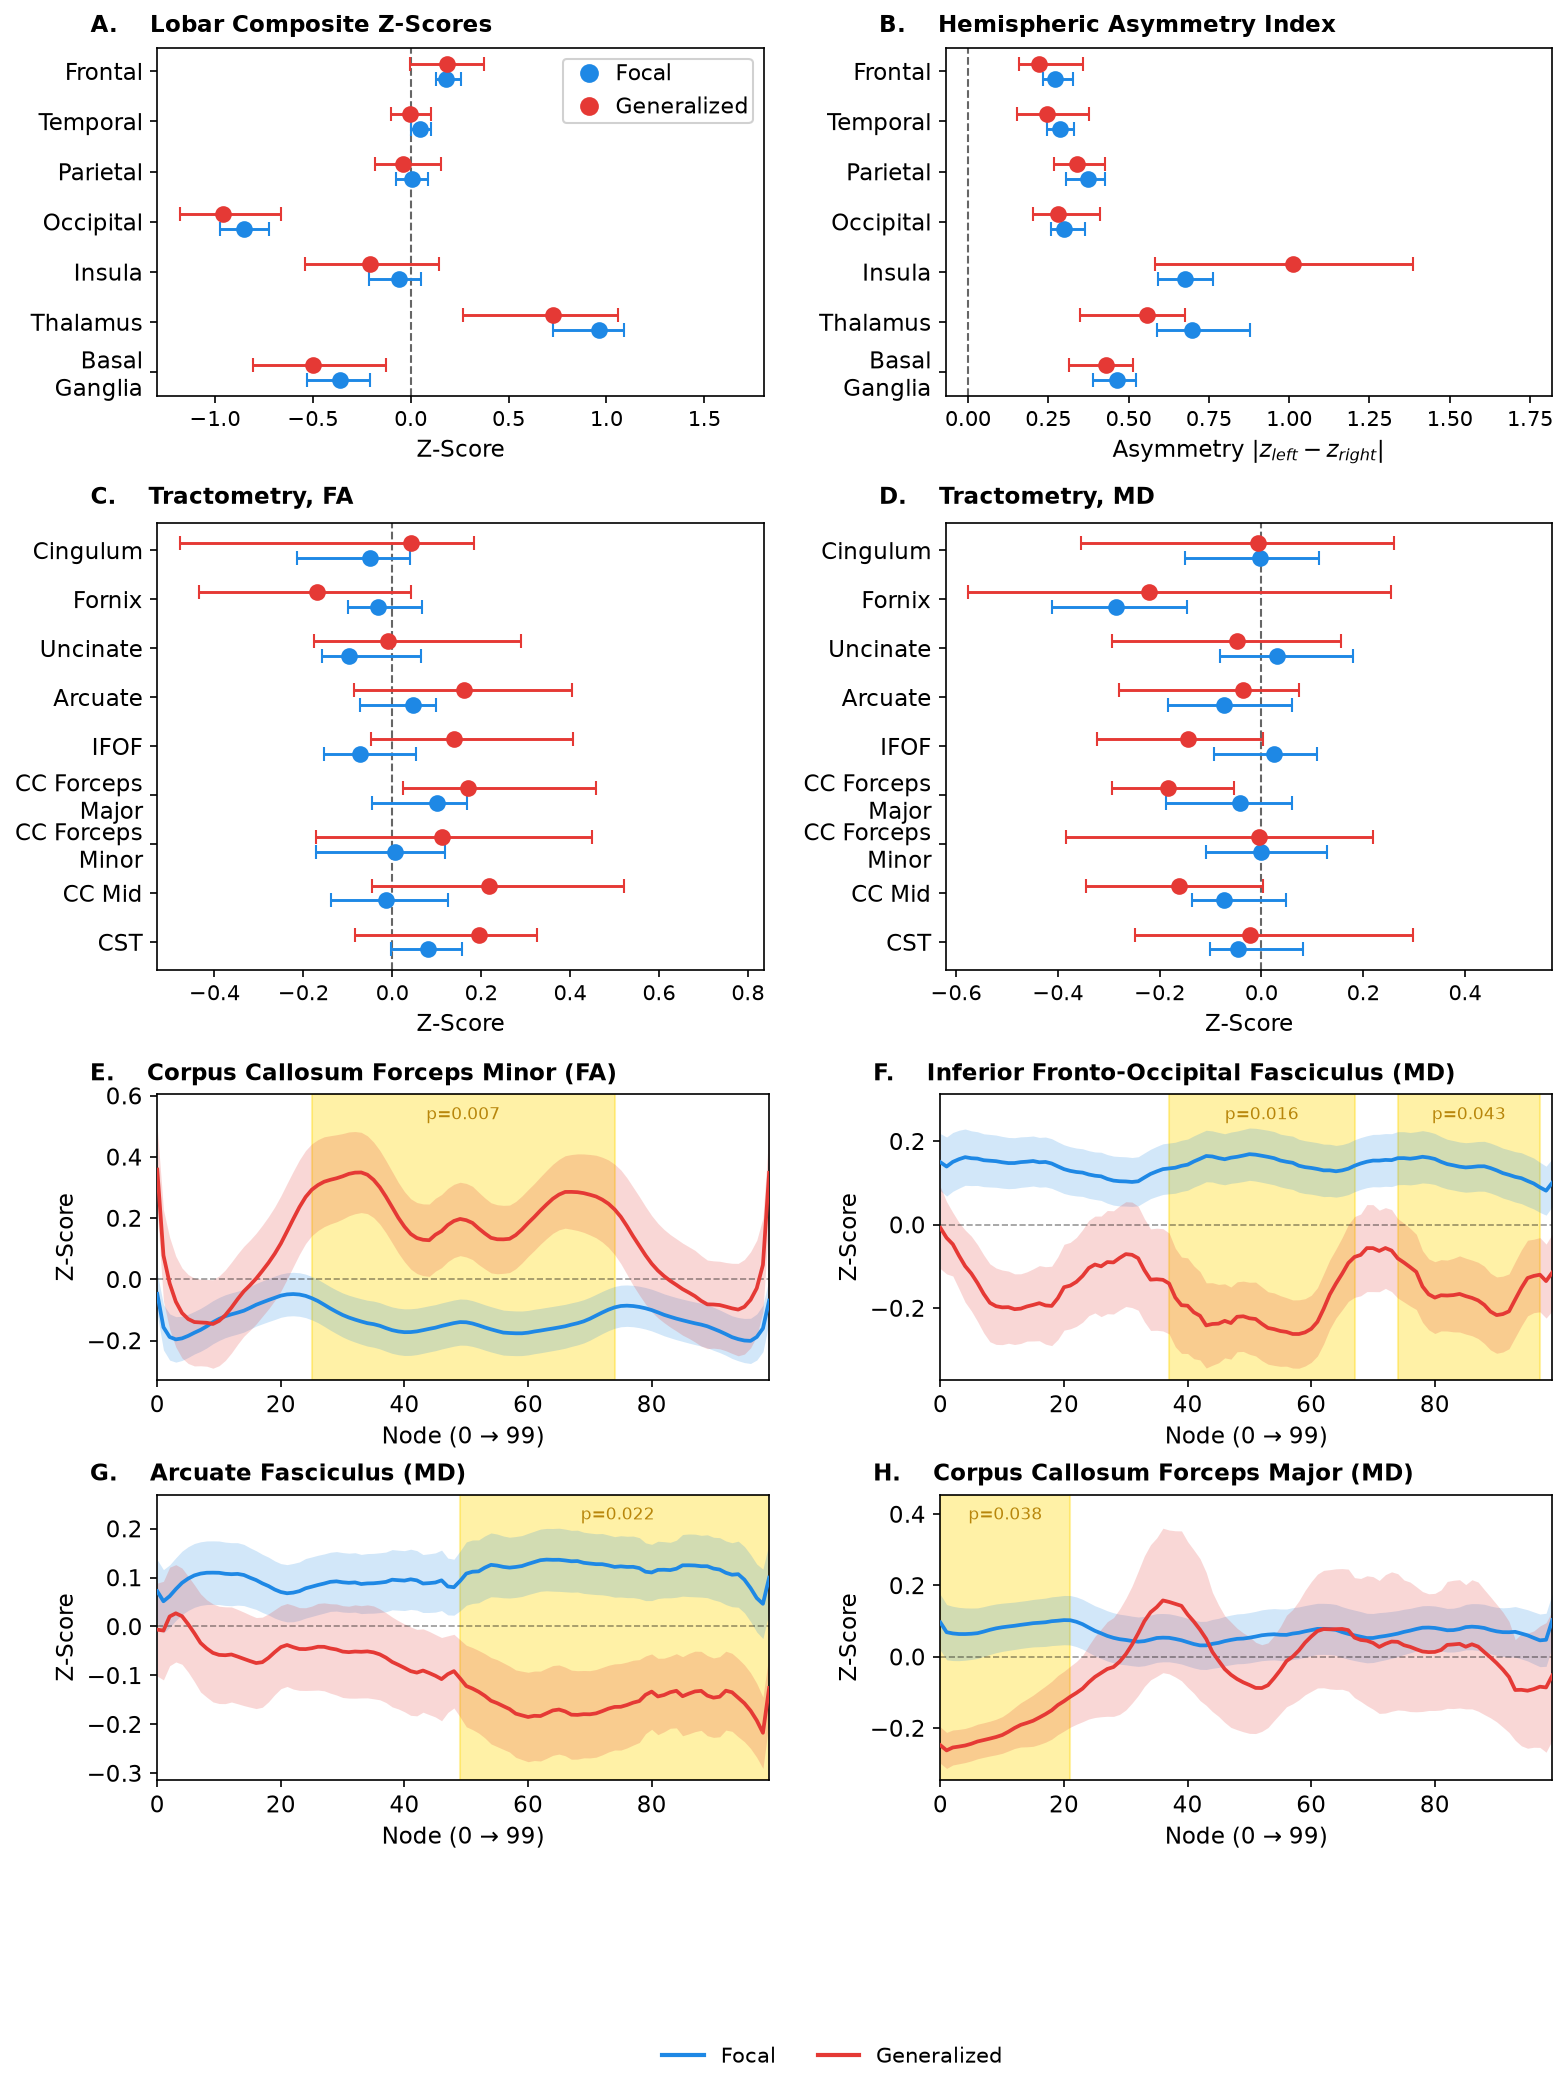

In [10]:
build_full_comparison_figure('Focal', 'Generalized', 'Focal', 'Generalized',
                              'figure3_dotplot.pdf')

## Figure 4: Drug-Resistant vs. Drug-Responsive

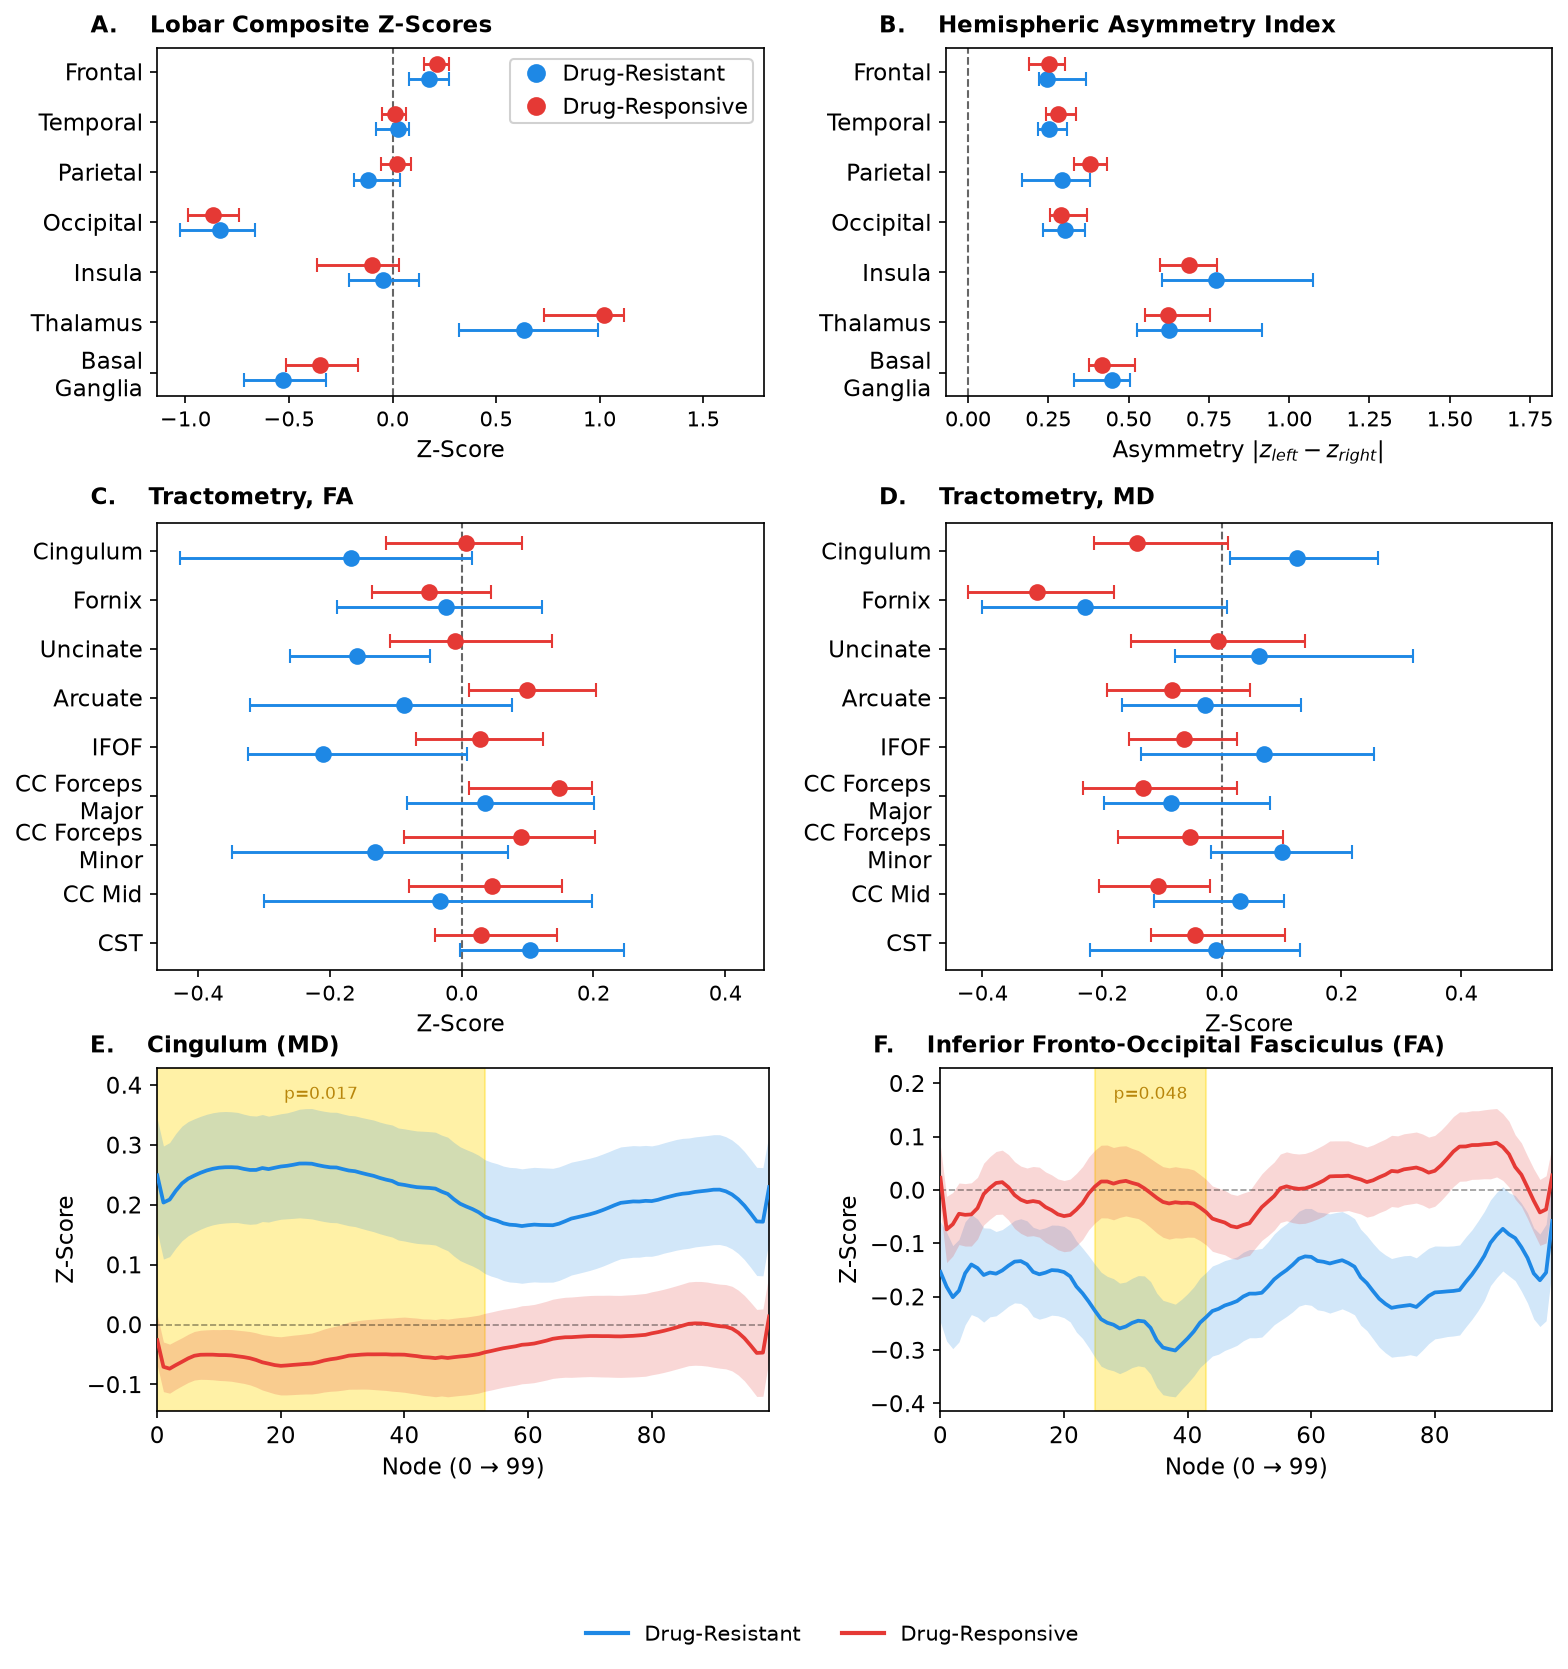

In [11]:
build_full_comparison_figure('DR', 'DS', 'Drug-Resistant', 'Drug-Responsive',
                              'figure4_dotplot.pdf')

## 4d. Split Versions: Forest Plots and Along-Tract Plots as Separate Figures

Same panels as the combined Figures 2-4 above, split into two standalone figures per comparison: the
2x2 dot+CI forest grid (panels A-D) and the along-tract cluster panels (relabeled from A). Comparisons
with no significant along-tract clusters get no along-tract figure. Saved as
`figure{2,3,4}_dotplot_forest.pdf` and `figure{2,3,4}_dotplot_along_tract.pdf`; the combined
`figure{2,3,4}_dotplot.pdf` files are unchanged.

=== figure2: Epilepsy vs FS ===


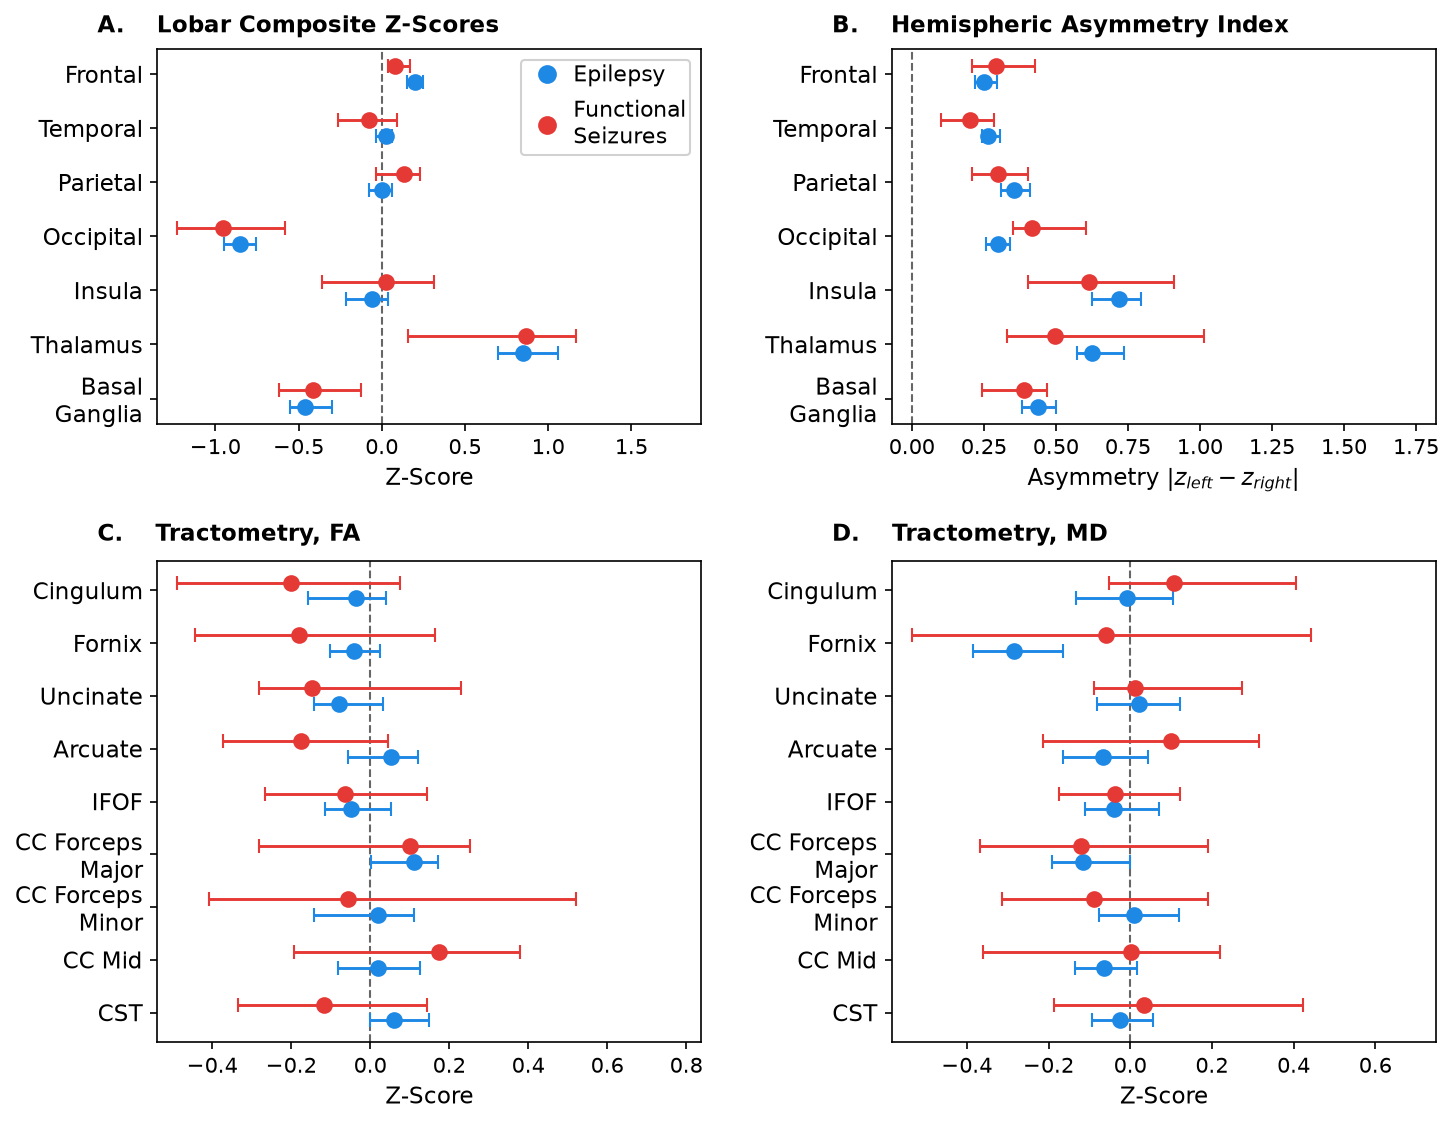

Epilepsy vs FS: no significant along-tract clusters -- no along-tract figure.
=== figure3: Focal vs Generalized ===


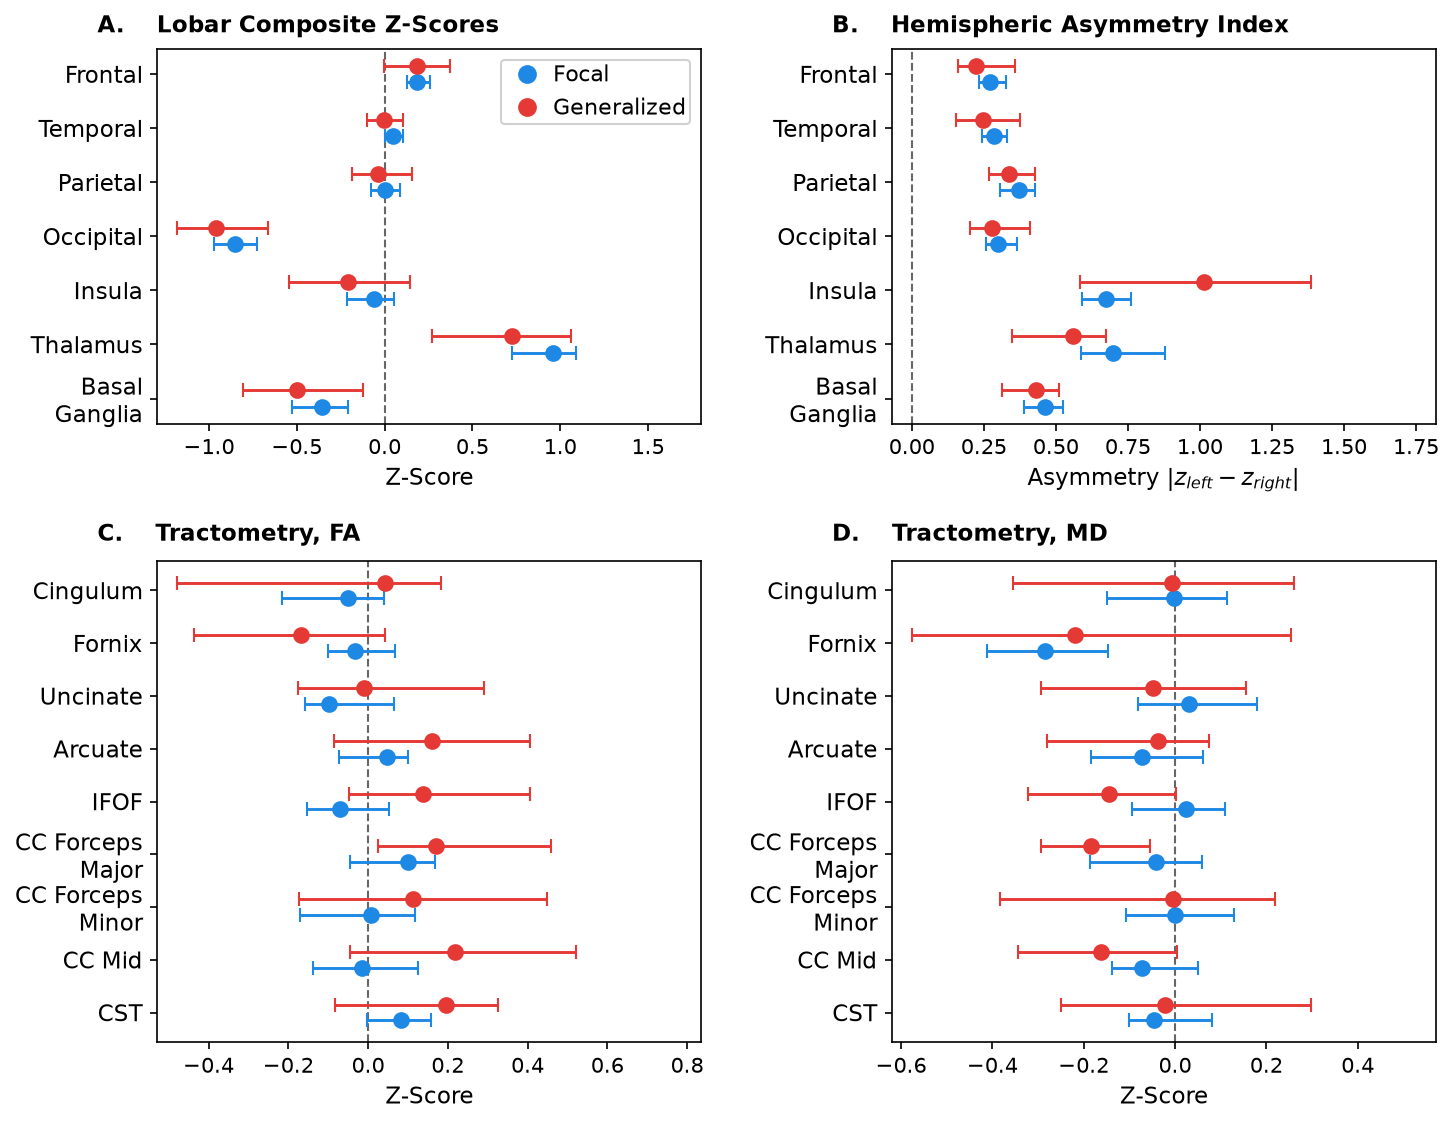

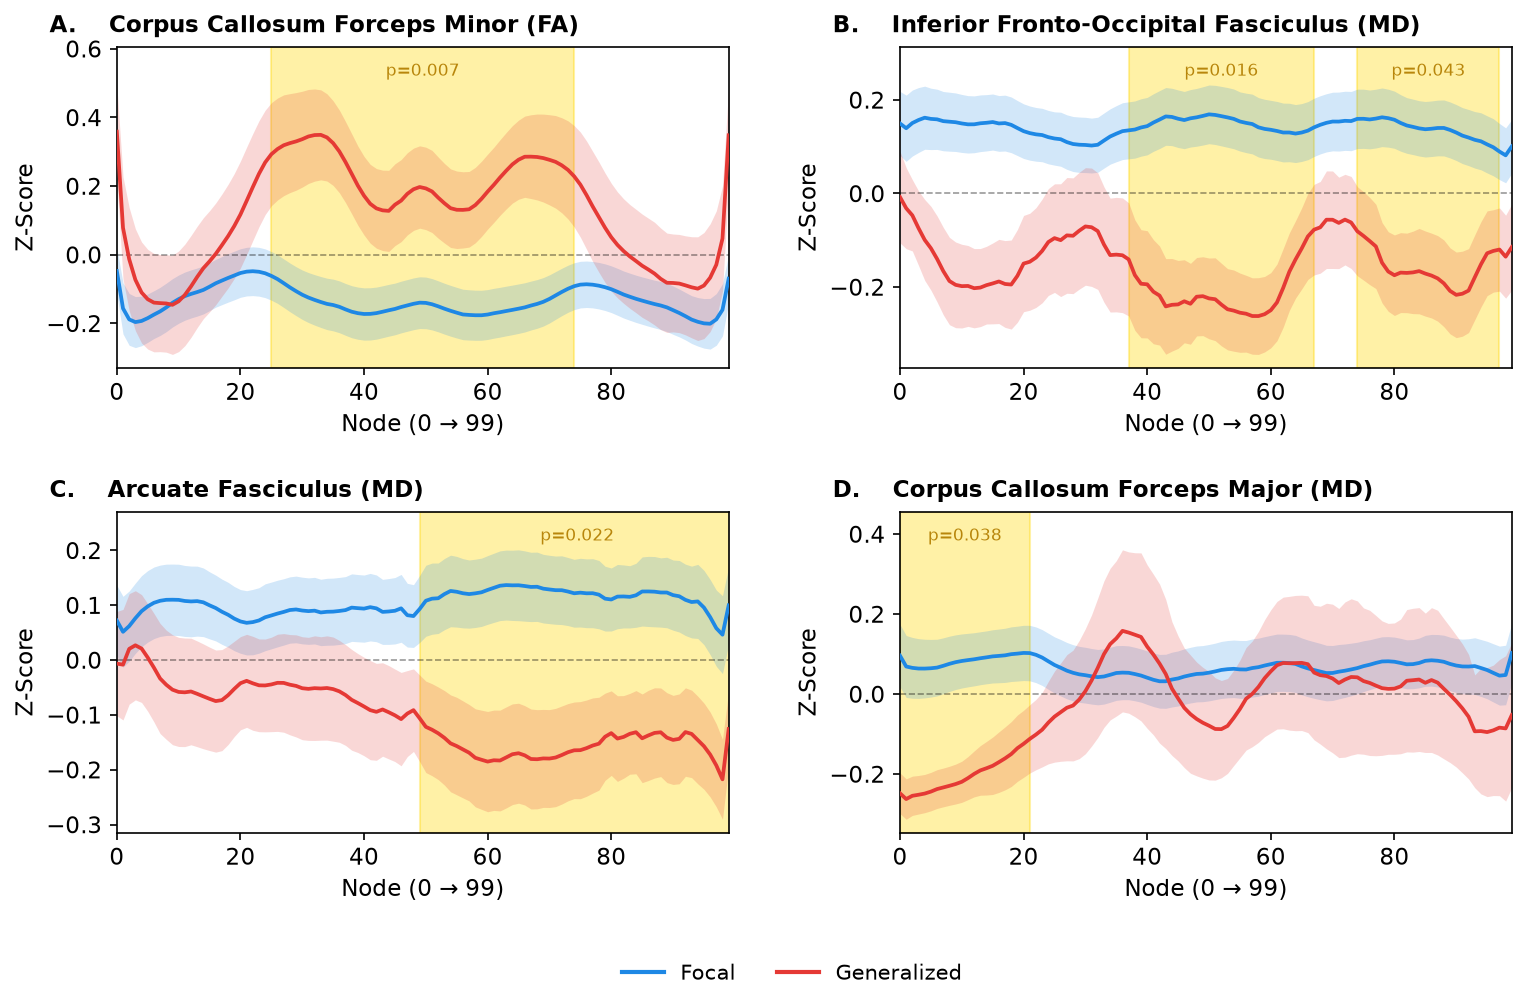

=== figure4: DR vs DS ===


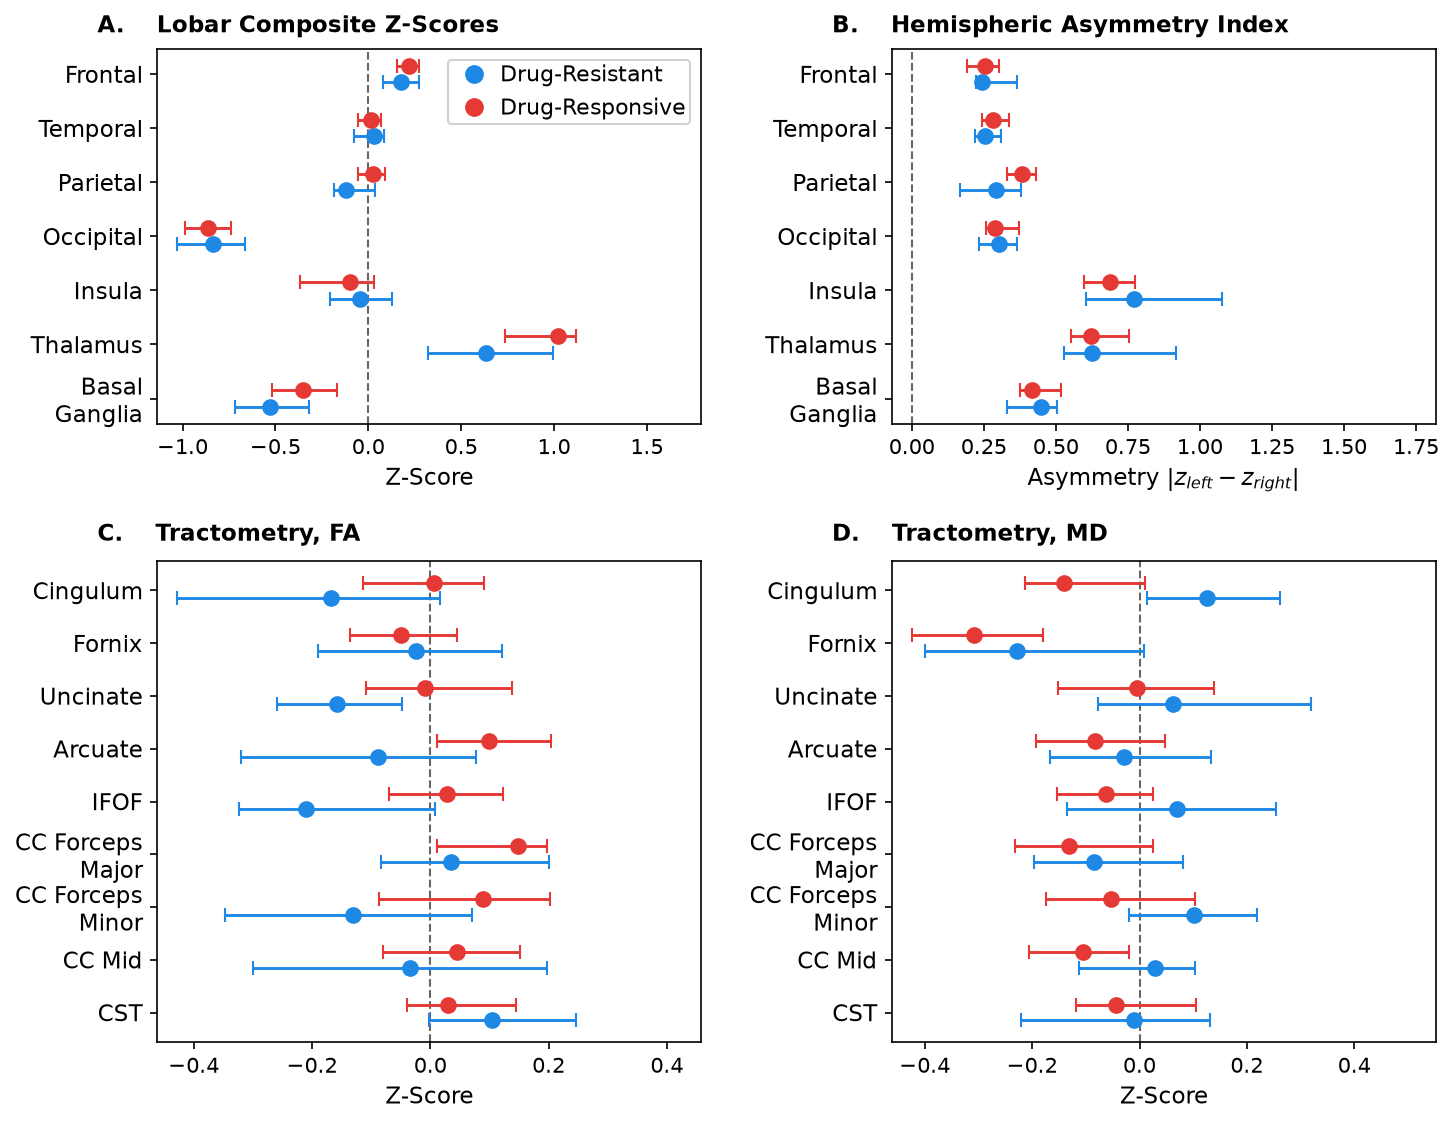

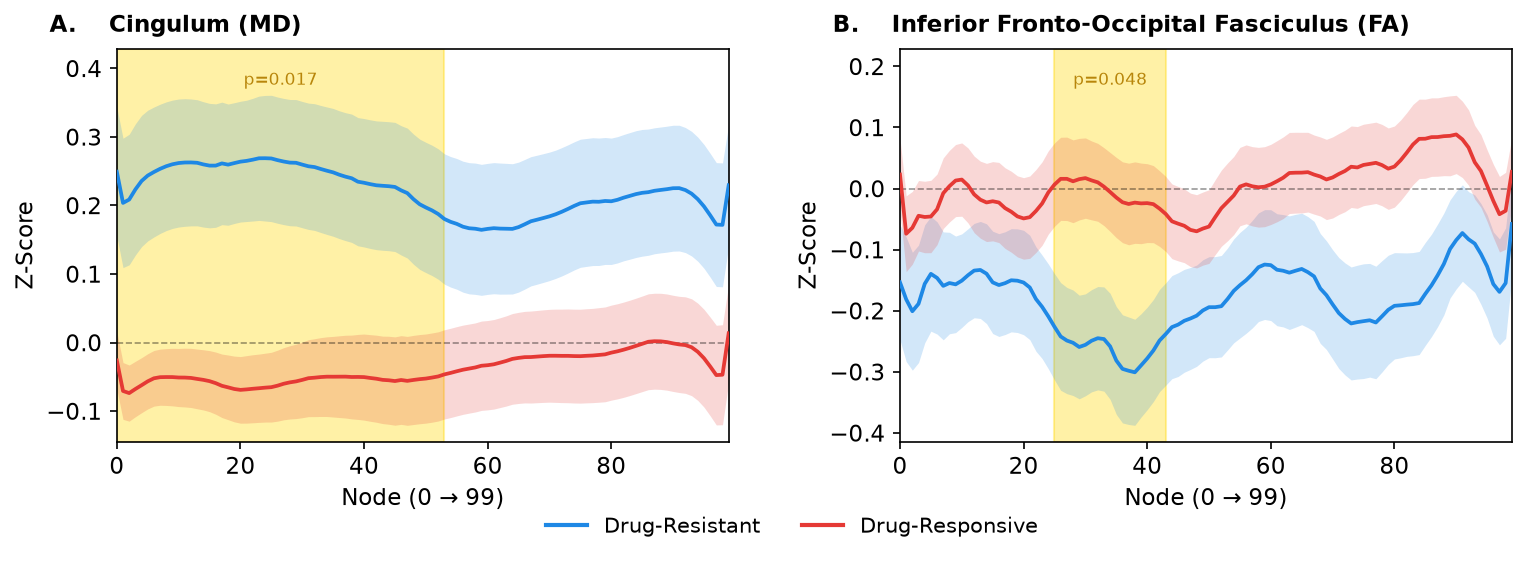

In [12]:
def build_forest_figure(group_a, group_b, label_a, label_b, save_name):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.6),
                              gridspec_kw={'height_ratios': [len(lobe_order), len(tract_row_labels)],
                                           'wspace': 0.35, 'hspace': 0.32})
    draw_forest_grid(axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1], group_a, group_b, label_a, label_b)
    plt.savefig(f'../outputs/{save_name}', bbox_inches='tight', dpi=300)
    plt.savefig(f'../outputs/{save_name.replace(".pdf", ".png")}', bbox_inches='tight', dpi=300)
    plt.show()

def build_along_tract_figure(group_a, group_b, label_a, label_b, save_name):
    sig_groups = sig_cluster_groups((group_a, group_b))
    n_sig = len(sig_groups)
    if n_sig == 0:
        print(f'{group_a} vs {group_b}: no significant along-tract clusters -- no along-tract figure.')
        return
    n_cols = min(2, n_sig)
    n_rows = int(np.ceil(n_sig / n_cols))
    fig = plt.figure(figsize=(6 * n_cols, 3.4 * n_rows))
    gs = fig.add_gridspec(n_rows, n_cols, wspace=0.28, hspace=0.45)
    draw_along_tract_grid(fig, gs, sig_groups, group_a, group_b, label_a, label_b, n_cols, first_label='A')
    plt.savefig(f'../outputs/{save_name}', bbox_inches='tight', dpi=300)
    plt.savefig(f'../outputs/{save_name.replace(".pdf", ".png")}', bbox_inches='tight', dpi=300)
    plt.show()

split_specs = [('Epilepsy', 'FS', 'Epilepsy', 'Functional\nSeizures', 'figure2'),
               ('Focal', 'Generalized', 'Focal', 'Generalized', 'figure3'),
               ('DR', 'DS', 'Drug-Resistant', 'Drug-Responsive', 'figure4')]
for ga, gb, la, lb, stem in split_specs:
    print(f'=== {stem}: {ga} vs {gb} ===')
    build_forest_figure(ga, gb, la, lb, f'{stem}_dotplot_forest.pdf')
    build_along_tract_figure(ga, gb, la, lb, f'{stem}_dotplot_along_tract.pdf')

## 5. Table of Results: AUC, Bootstrap CI, FDR q-value

In [13]:
def fold_auc(auc, ci_lo, ci_hi):
    if auc >= 0.5:
        return auc, ci_lo, ci_hi
    return 1 - auc, 1 - ci_hi, 1 - ci_lo

rows = []
for ga, gb, la, lb in comparisons:
    key = (ga, gb)
    comp_label = f'{la} vs. {lb}'

    m_res = morph_auc_results[key]
    for i, lobe in enumerate(lobe_order):
        rows.append({'Comparison': comp_label, 'Domain': 'Morphometry (Z-score)', 'Region/Tract': lobe,
                     'AUC': m_res['auc'][i], 'CI_lo': m_res['ci_lo'][i], 'CI_hi': m_res['ci_hi'][i],
                     'p': m_res['p'][i], 'q': m_res['q'][i], 'Higher In': la if m_res['auc'][i] >= 0.5 else lb})

    a_res = morph_asym_auc_results[key]
    for i, lobe in enumerate(lobe_order):
        rows.append({'Comparison': comp_label, 'Domain': 'Morphometry (Asymmetry)', 'Region/Tract': lobe,
                     'AUC': a_res['auc'][i], 'CI_lo': a_res['ci_lo'][i], 'CI_hi': a_res['ci_hi'][i],
                     'p': a_res['p'][i], 'q': a_res['q'][i], 'Higher In': la if a_res['auc'][i] >= 0.5 else lb})

    fa_res, md_res = tract_auc_results[key]
    for i, tract in enumerate(tract_order):
        rows.append({'Comparison': comp_label, 'Domain': 'Tractometry (FA)', 'Region/Tract': tract,
                     'AUC': fa_res['auc'][i], 'CI_lo': fa_res['ci_lo'][i], 'CI_hi': fa_res['ci_hi'][i],
                     'p': fa_res['p'][i], 'q': fa_res['q'][i], 'Higher In': la if fa_res['auc'][i] >= 0.5 else lb})
    for i, tract in enumerate(tract_order):
        rows.append({'Comparison': comp_label, 'Domain': 'Tractometry (MD)', 'Region/Tract': tract,
                     'AUC': md_res['auc'][i], 'CI_lo': md_res['ci_lo'][i], 'CI_hi': md_res['ci_hi'][i],
                     'p': md_res['p'][i], 'q': md_res['q'][i], 'Higher In': la if md_res['auc'][i] >= 0.5 else lb})

results_table = pd.DataFrame(rows)
# Fold AUC (and its CI) to magnitude form (max(AUC, 1-AUC), always >= 0.5) so "bigger number = stronger
# discrimination" holds universally -- direction is carried separately by the "Higher In" column instead
# of by the sign of (AUC - 0.5), which read unintuitively (e.g. AUC=0.25 looking "weak" when it's the
# same strength as 0.75).
folded = results_table.apply(lambda r: fold_auc(r['AUC'], r['CI_lo'], r['CI_hi']), axis=1, result_type='expand')
results_table[['AUC', 'CI_lo', 'CI_hi']] = folded
results_table['AUC (95% CI)'] = results_table.apply(
    lambda r: f"{r['AUC']:.3f} ({r['CI_lo']:.3f}-{r['CI_hi']:.3f})", axis=1)
results_table['p'] = results_table['p'].round(4)
results_table['q'] = results_table['q'].round(4)

results_table = results_table[['Comparison', 'Domain', 'Region/Tract', 'AUC (95% CI)', 'Higher In', 'p', 'q']]
results_table.to_csv('../outputs/table_auc_results.csv', index=False)
display(results_table)


,Comparison,Domain,Region/Tract,AUC (95% CI),Higher In,p,q
0,Epilepsy vs. Functional Seizures,Morphometry (Z-score),Frontal,0.569 (0.482-0.654),Epilepsy,0.1995,0.6984
1,Epilepsy vs. Functional Seizures,Morphometry (Z-score),Temporal,0.554 (0.460-0.649),Epilepsy,0.3158,0.7368
2,Epilepsy vs. Functional Seizures,Morphometry (Z-score),Parietal,0.594 (0.500-0.685),Functional Seizures,0.0814,0.5698
3,Epilepsy vs. Functional Seizures,Morphometry (Z-score),Occipital,0.527 (0.427-0.629),Epilepsy,0.6223,0.8450
4,Epilepsy vs. Functional Seizures,Morphometry (Z-score),Insula,0.529 (0.430-0.628),Functional Seizures,0.5941,0.8450
...,...,...,...,...,...,...,...
91,Drug-Resistant vs. Drug-Responsive,Tractometry (MD),IFOF,0.549 (0.477-0.621),Drug-Resistant,0.1777,0.2908
92,Drug-Resistant vs. Drug-Responsive,Tractometry (MD),CC Forceps Major,0.522 (0.449-0.592),Drug-Resistant,0.5540,0.6232
93,Drug-Resistant vs. Drug-Responsive,Tractometry (MD),CC Forceps Minor,0.562 (0.491-0.632),Drug-Resistant,0.0928,0.2368
94,Drug-Resistant vs. Drug-Responsive,Tractometry (MD),CC Mid,0.558 (0.486-0.628),Drug-Resistant,0.1130,0.2368


## 5b. Supplementary Tables: One Morphometry + One Tractometry Table per Comparison

Wide format, one row per region/tract, columns grouped by metric (Morphometry Z-score / Asymmetry;
Tractometry FA / MD), each with an `AUC (95% CI)` and `q-value` sub-column. Six tables total (2 domains
x 3 comparisons), saved individually to `../outputs/` so each can be dropped into supplementary
materials on its own.

In [14]:
tract_full_names = {
    'Cingulum': 'Cingulum', 'Fornix': 'Fornix', 'Uncinate': 'Uncinate Fasciculus',
    'Arcuate': 'Arcuate Fasciculus', 'IFOF': 'Inferior Fronto-Occipital Fasciculus',
    'CC Forceps Major': 'Corpus Callosum Forceps Major', 'CC Forceps Minor': 'Corpus Callosum Forceps Minor',
    'CC Mid': 'Corpus Callosum Body', 'CST': 'Corticospinal Tract',
}

def fmt_auc_ci(auc, lo, hi):
    f_auc, f_lo, f_hi = fold_auc(auc, lo, hi)
    return f'{f_auc:.3f} ({f_lo:.3f}-{f_hi:.3f})'

def fmt_direction(auc, label_a, label_b):
    return label_a if auc >= 0.5 else label_b

def fmt_q(q):
    return '<0.001' if q < 0.001 else f'{q:.3f}'

def build_morph_supp_table(key, la, lb):
    m_res = morph_auc_results[key]
    a_res = morph_asym_auc_results[key]
    rows = []
    for i, lobe in enumerate(lobe_order):
        rows.append({
            ('Morphometry (Z-score)', 'AUC (95% CI)'): fmt_auc_ci(m_res['auc'][i], m_res['ci_lo'][i], m_res['ci_hi'][i]),
            ('Morphometry (Z-score)', 'Higher In'): fmt_direction(m_res['auc'][i], la, lb),
            ('Morphometry (Z-score)', 'q-value'): fmt_q(m_res['q'][i]),
            ('Morphometry (Asymmetry)', 'AUC (95% CI)'): fmt_auc_ci(a_res['auc'][i], a_res['ci_lo'][i], a_res['ci_hi'][i]),
            ('Morphometry (Asymmetry)', 'Higher In'): fmt_direction(a_res['auc'][i], la, lb),
            ('Morphometry (Asymmetry)', 'q-value'): fmt_q(a_res['q'][i]),
        })
    out = pd.DataFrame(rows, index=lobe_order)
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    out.index.name = None
    return out

def build_tract_supp_table(key, la, lb):
    fa_res, md_res = tract_auc_results[key]
    rows = []
    for i, tract in enumerate(tract_order):
        rows.append({
            ('Tractometry (FA)', 'AUC (95% CI)'): fmt_auc_ci(fa_res['auc'][i], fa_res['ci_lo'][i], fa_res['ci_hi'][i]),
            ('Tractometry (FA)', 'Higher In'): fmt_direction(fa_res['auc'][i], la, lb),
            ('Tractometry (FA)', 'q-value'): fmt_q(fa_res['q'][i]),
            ('Tractometry (MD)', 'AUC (95% CI)'): fmt_auc_ci(md_res['auc'][i], md_res['ci_lo'][i], md_res['ci_hi'][i]),
            ('Tractometry (MD)', 'Higher In'): fmt_direction(md_res['auc'][i], la, lb),
            ('Tractometry (MD)', 'q-value'): fmt_q(md_res['q'][i]),
        })
    out = pd.DataFrame(rows, index=[tract_full_names[t] for t in tract_order])
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    out.index.name = None
    return out

supp_tables = {}
for ga, gb, la, lb in comparisons:
    key = (ga, gb)
    slug = f'{ga}_vs_{gb}'.lower()
    morph_tbl = build_morph_supp_table(key, la, lb)
    tract_tbl = build_tract_supp_table(key, la, lb)
    supp_tables[(key, 'morphometry')] = morph_tbl
    supp_tables[(key, 'tractometry')] = tract_tbl
    morph_tbl.to_csv(f'../outputs/table_supp_morphometry_{slug}.csv')
    tract_tbl.to_csv(f'../outputs/table_supp_tractometry_{slug}.csv')

print('Example -- Epilepsy vs. Functional Seizures:')
display(supp_tables[(('Epilepsy', 'FS'), 'morphometry')])
display(supp_tables[(('Epilepsy', 'FS'), 'tractometry')])

Example -- Epilepsy vs. Functional Seizures:


Morphometry (Z-score)                               \
                       AUC (95% CI)            Higher In q-value   
Frontal         0.569 (0.482-0.654)             Epilepsy   0.698   
Temporal        0.554 (0.460-0.649)             Epilepsy   0.737   
Parietal        0.594 (0.500-0.685)  Functional Seizures   0.570   
Occipital       0.527 (0.427-0.629)             Epilepsy   0.845   
Insula          0.529 (0.430-0.628)  Functional Seizures   0.845   
Thalamus        0.501 (0.401-0.601)             Epilepsy   0.989   
Basal Ganglia   0.519 (0.430-0.613)  Functional Seizures   0.845   

              Morphometry (Asymmetry)                               
                         AUC (95% CI)            Higher In q-value  
Frontal           0.573 (0.465-0.677)  Functional Seizures   0.307  
Temporal          0.603 (0.510-0.695)             Epilepsy   0.196  
Parietal          0.548 (0.450-0.645)             Epilepsy   0.439  
Occipital         0.612 (0.501-0.717)  Functional Seizures   0.196  
Insula            0.549 (0.446-0.648)             Epilepsy   0.439  
Thalamus          0.531 (0.411-0.649)             Epilepsy   0.569  
Basal Ganglia     0.588 (0.490-0.685)             Epilepsy   0.237

Tractometry (FA)  \
                                             AUC (95% CI)   
Cingulum                              0.534 (0.422-0.642)   
Fornix                                0.556 (0.448-0.664)   
Uncinate Fasciculus                   0.504 (0.395-0.615)   
Arcuate Fasciculus                    0.534 (0.422-0.640)   
Inferior Fronto-Occipital Fasciculus  0.518 (0.409-0.630)   
Corpus Callosum Forceps Major         0.541 (0.433-0.647)   
Corpus Callosum Forceps Minor         0.538 (0.431-0.650)   
Corpus Callosum Body                  0.551 (0.441-0.661)   
Corticospinal Tract                   0.611 (0.502-0.719)   

                                                                   \
                                                Higher In q-value   
Cingulum                                         Epilepsy   0.872   
Fornix                                           Epilepsy   0.872   
Uncinate Fasciculus                   Functional Seizures   0.940   
Arcuate Fasciculus                               Epilepsy   0.872   
Inferior Fronto-Occipital Fasciculus  Functional Seizures   0.940   
Corpus Callosum Forceps Major                    Epilepsy   0.872   
Corpus Callosum Forceps Minor         Functional Seizures   0.872   
Corpus Callosum Body                  Functional Seizures   0.872   
Corticospinal Tract                              Epilepsy   0.723   

                                         Tractometry (MD)  \
                                             AUC (95% CI)   
Cingulum                              0.545 (0.435-0.651)   
Fornix                                0.535 (0.431-0.638)   
Uncinate Fasciculus                   0.517 (0.417-0.623)   
Arcuate Fasciculus                    0.510 (0.401-0.617)   
Inferior Fronto-Occipital Fasciculus  0.511 (0.410-0.620)   
Corpus Callosum Forceps Major         0.506 (0.402-0.612)   
Corpus Callosum Forceps Minor         0.544 (0.443-0.648)   
Corpus Callosum Body                  0.512 (0.405-0.623)   
Corticospinal Tract                   0.589 (0.486-0.686)   

                                                                   
                                                Higher In q-value  
Cingulum                              Functional Seizures   0.872  
Fornix                                Functional Seizures   0.872  
Uncinate Fasciculus                              Epilepsy   0.940  
Arcuate Fasciculus                    Functional Seizures   0.940  
Inferior Fronto-Occipital Fasciculus             Epilepsy   0.940  
Corpus Callosum Forceps Major                    Epilepsy   0.940  
Corpus Callosum Forceps Minor                    Epilepsy   0.872  
Corpus Callosum Body                             Epilepsy   0.940  
Corticospinal Tract                   Functional Seizures   0.872

## 6. Syncope Calibration Check (Exploratory, Not in Manuscript)

Syncope subjects have no expected neuro-structural pathology, so they're a second "should be near-zero"
population alongside FS -- checking whether their z-scores actually behave that way, the same
Wilcoxon-vs-zero + abnormality-burden checks used to validate FS's calibration earlier. n=25 (morphometry)
/ 26 (tractometry), the subset of the 33 syncope subjects in metadata with usable z-score data (see
`metadata_summary.ipynb` for the full modality-coverage breakdown).

In [15]:
from scipy.stats import wilcoxon

syncope_m = morph[morph['group_1'] == 'syncope'].copy()
syncope_t = wide[wide['group_1'] == 'syncope'].copy()
print(f'Syncope -- morphometry n={len(syncope_m)}, tractometry n={len(syncope_t)}')

def wilcoxon_family(df, cols):
    rows = []
    for c in cols:
        vals = df[c].dropna().values
        stat, p = wilcoxon(vals)
        rows.append({'feature': c, 'median': np.median(vals), 'p': p})
    tbl = pd.DataFrame(rows)
    tbl['q'] = multipletests(tbl['p'], method='fdr_bh')[1]
    return tbl

print('\n=== Morphometry composite z, Wilcoxon vs 0 (syncope) ===')
print(wilcoxon_family(syncope_m, morph_cols).round(4).to_string(index=False))
print('\n=== Asymmetry, Wilcoxon vs 0 (syncope) ===')
print(wilcoxon_family(syncope_m, morph_asym_cols).round(4).to_string(index=False))
print('\n=== Tractometry FA, Wilcoxon vs 0 (syncope) ===')
print(wilcoxon_family(syncope_t, tract_cols_fa).round(4).to_string(index=False))
print('\n=== Tractometry MD, Wilcoxon vs 0 (syncope) ===')
print(wilcoxon_family(syncope_t, tract_cols_md).round(4).to_string(index=False))

# Whole-brain / whole-tractometry abnormality burden (|z|>2), same convention as the FS calibration
# check in morphometry_abnormality_burden.ipynb -- chance expectation at |z|>2 two-tailed is ~4.55%.
roi_cols = [c for c in ct.columns if c not in ['SITE', 'SubjectID', 'Vendor', 'FreeSurfer_Version', 'age', 'sex']] + sv_zcols
syncope_m['n_abnormal_82roi'] = (syncope_m[roi_cols].abs() > 2).sum(axis=1)
fs_burden = (fs_m[roi_cols].abs() > 2).sum(axis=1)
print(f'\n=== Whole-brain morphometry abnormality burden (|z|>2 across 82 ROIs) ===')
print(f"Syncope: median {syncope_m['n_abnormal_82roi'].median():.0f}/82 "
      f"({100*syncope_m['n_abnormal_82roi'].median()/82:.1f}%), n={len(syncope_m)}")
print(f"FS:      median {fs_burden.median():.0f}/82 ({100*fs_burden.median()/82:.1f}%), n={len(fs_m)}")
print('Chance expectation at |z|>2, two-tailed: ~4.55%')

syncope_t['n_abnormal_18'] = (syncope_t[tract_cols_all18].abs() > 2).sum(axis=1)
print(f"\nSyncope whole-tractometry burden: median {syncope_t['n_abnormal_18'].median():.0f}/18 "
      f"({100*syncope_t['n_abnormal_18'].median()/18:.1f}%)")

Syncope -- morphometry n=25, tractometry n=25

=== Morphometry composite z, Wilcoxon vs 0 (syncope) ===
        feature  median      p      q
      z_Frontal  0.1552 0.0006 0.0013
     z_Temporal -0.0422 0.7112 0.7112
     z_Parietal  0.0962 0.1645 0.2303
    z_Occipital -0.9669 0.0000 0.0000
       z_Insula  0.2737 0.7112 0.7112
     z_Thalamus  1.0140 0.0003 0.0012
z_Basal Ganglia -0.0878 0.1266 0.2216

=== Asymmetry, Wilcoxon vs 0 (syncope) ===
           feature  median   p   q
      asym_Frontal  0.2453 0.0 0.0
     asym_Temporal  0.2641 0.0 0.0
     asym_Parietal  0.3119 0.0 0.0
    asym_Occipital  0.3663 0.0 0.0
       asym_Insula  0.6042 0.0 0.0
     asym_Thalamus  0.5819 0.0 0.0
asym_Basal Ganglia  0.3602 0.0 0.0

=== Tractometry FA, Wilcoxon vs 0 (syncope) ===
                   feature  median      p      q
        zb_Cingulum_dti_fa -0.0134 0.6528 0.7510
          zb_Fornix_dti_fa -0.0328 0.7510 0.7510
        zb_Uncinate_dti_fa  0.0191 0.5782 0.7510
         zb_Arcuate_dti

## 7. Figure 5: AUC Brain Maps

Each region or tract is colored by its AUC from `table_auc_results.csv`, shown as max(AUC, 1 - AUC) on a
0.50-1.00 scale in either direction; hue shows which group had the higher value (red = first-named group, blue =
second). Lobar composite and asymmetry values are painted onto every Desikan-Killiany region in that lobe (hippocampus
and amygdala carry the temporal value; thalamus and basal ganglia their own). Tracts use the XTRACT atlas; the
callosal body (CC Mid) has no XTRACT counterpart and is not drawn.

In [16]:
import yabplot as yb
from matplotlib import cm, colors as mcolors

FIG5_VMAX = 0.5  # signed (AUC - 0.5): color scale spans AUC 0.50-1.00 in each direction
auc_tbl = pd.read_csv('../outputs/table_auc_results.csv')
auc_tbl['auc'] = auc_tbl['AUC (95% CI)'].str.split(' ').str[0].astype(float)
if (auc_tbl['q'] < 0.05).any():
    print('WARNING: significant features exist but Figure 5 does not mark significance:')
    print(auc_tbl[auc_tbl['q'] < 0.05])

fig5_comparisons = [('Epilepsy vs. Functional Seizures', 'Epilepsy', 'Functional Seizures', 'Epilepsy\nvs. Functional Seizures'),
                    ('Focal vs. Generalized', 'Focal', 'Generalized', 'Focal\nvs. Generalized'),
                    ('Drug-Resistant vs. Drug-Responsive', 'Drug-Resistant', 'Drug-Responsive', 'Drug-Resistant\nvs. Drug-Responsive')]

def signed_auc(comp, domain, region, first_group):
    row = auc_tbl[(auc_tbl['Comparison'] == comp) & (auc_tbl['Domain'] == domain) & (auc_tbl['Region/Tract'] == region)]
    assert len(row) == 1, (comp, domain, region, len(row))
    r = row.iloc[0]
    return (r['auc'] - 0.5) * (1 if r['Higher In'] == first_group else -1)

aseg_to_lobe = {'Thalamus': 'Thalamus', 'Caudate': 'Basal Ganglia', 'Putamen': 'Basal Ganglia',
                'Pallidum': 'Basal Ganglia', 'Accumbens-area': 'Basal Ganglia',
                'Hippocampus': 'Temporal', 'Amygdala': 'Temporal'}
tract_to_xtract = {'Cingulum': ['Cing_Dorsal_L', 'Cing_Dorsal_R'], 'Fornix': ['Fornix_L', 'Fornix_R'],
                   'Uncinate': ['UF_L', 'UF_R'], 'Arcuate': ['AF_L', 'AF_R'], 'IFOF': ['IFOF_L', 'IFOF_R'],
                   'CC Forceps Major': ['FMaj'], 'CC Forceps Minor': ['FMin'], 'CST': ['CST_L', 'CST_R']}
aparc_regions = yb.get_atlas_regions('aparc', 'cortical')
aseg_regions = yb.get_atlas_regions('aseg', 'subcortical')
xtract_regions = yb.get_atlas_regions('xtract_small', 'tracts')
missing = [r for lobe in ['Frontal', 'Temporal', 'Parietal', 'Occipital', 'Insula']
           for r in lobar_groups[lobe][0] for h in 'LR' if f'{h}_{r}' not in aparc_regions]
missing += [t for ts in tract_to_xtract.values() for t in ts if t not in xtract_regions]
assert not missing, f'atlas names not found: {missing}'

def cortical_data(comp, domain, first):
    d = {r: np.nan for r in aparc_regions}
    for lobe in ['Frontal', 'Temporal', 'Parietal', 'Occipital', 'Insula']:
        v = signed_auc(comp, domain, lobe, first)
        for r in lobar_groups[lobe][0]:
            d[f'L_{r}'] = d[f'R_{r}'] = v
    return d

def subcortical_data(comp, domain, first):
    d = {}
    for r in aseg_regions:
        struct = r.replace('Left-', '').replace('Right-', '')
        d[r] = signed_auc(comp, domain, aseg_to_lobe[struct], first)
    return d

def tract_data(comp, domain, first):
    d = {r: np.nan for r in xtract_regions}
    for tract, names in tract_to_xtract.items():
        v = signed_auc(comp, domain, tract, first)
        for n in names:
            d[n] = v
    return d

def render(ax, kind, data, views, zoom):
    kw = dict(data=data, cmap='RdBu_r', vminmax=[-FIG5_VMAX, FIG5_VMAX], views=views, zoom=zoom, display_type='object')
    if kind == 'cortical':
        pl = yb.plot_cortical(atlas='aparc', **kw)
    elif kind == 'subcortical':
        pl = yb.plot_subcortical(atlas='aseg', bmesh_alpha=0.0, **kw)
    else:
        pl = yb.plot_tracts(atlas='xtract_small', nan_alpha=0.0, bmesh_alpha=0.06, **kw)
    for name in list(pl.scalar_bars.keys()):
        pl.remove_scalar_bar(name)
    img = pl.screenshot(transparent_background=True, return_img=True, scale=3)
    pl.close()
    ax.imshow(img)
    ax.axis('off')

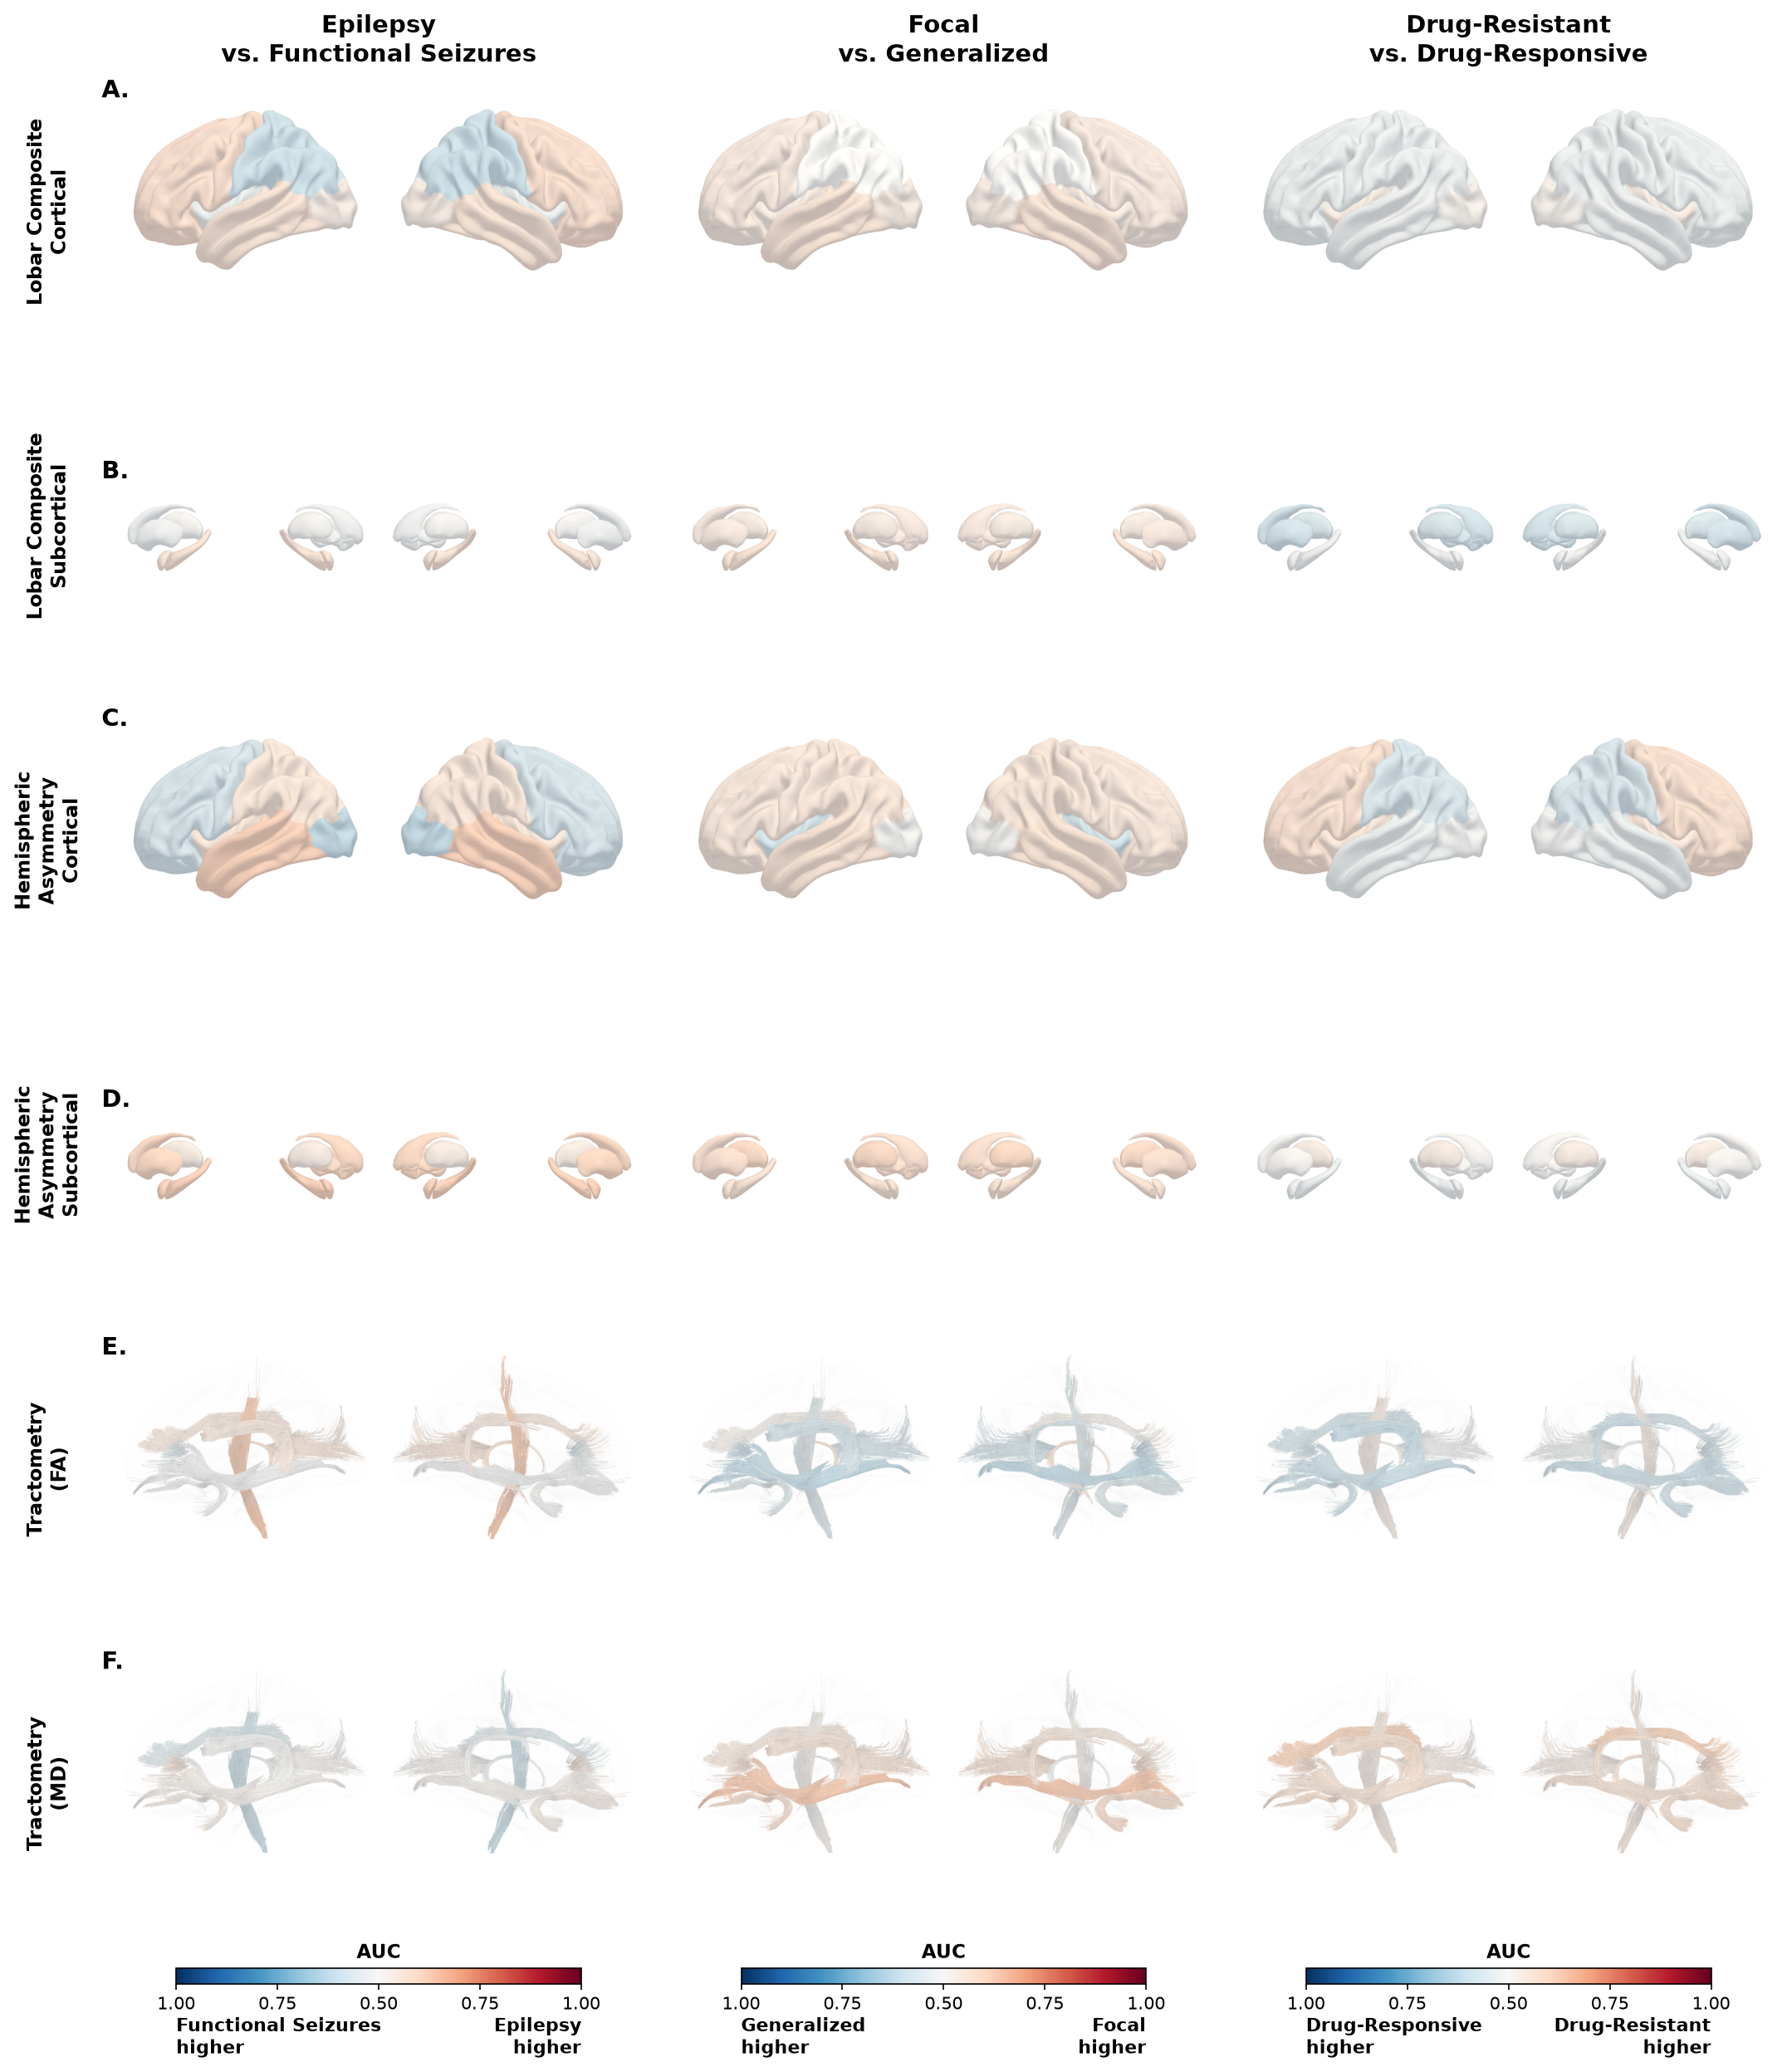

In [17]:
fig5_rows = [('A.', 'Lobar Composite\nCortical', 'cortical', 'Morphometry (Z-score)', ['left_lateral', 'right_lateral'], 1.3),
             ('B.', 'Lobar Composite\nSubcortical', 'subcortical', 'Morphometry (Z-score)',
              ['left_lateral', 'left_medial', 'right_medial', 'right_lateral'], 2.5),
             ('C.', 'Hemispheric\nAsymmetry\nCortical', 'cortical', 'Morphometry (Asymmetry)', ['left_lateral', 'right_lateral'], 1.3),
             ('D.', 'Hemispheric\nAsymmetry\nSubcortical', 'subcortical', 'Morphometry (Asymmetry)',
              ['left_lateral', 'left_medial', 'right_medial', 'right_lateral'], 2.5),
             ('E.', 'Tractometry\n(FA)', 'tracts', 'Tractometry (FA)', ['left_lateral', 'right_lateral'], 1.5),
             ('F.', 'Tractometry\n(MD)', 'tracts', 'Tractometry (MD)', ['left_lateral', 'right_lateral'], 1.5)]
builders = {'cortical': cortical_data, 'subcortical': subcortical_data, 'tracts': tract_data}

fig = plt.figure(figsize=(15, 17))
gs = fig.add_gridspec(len(fig5_rows) + 1, 3, height_ratios=[1] * len(fig5_rows) + [0.22],
                      hspace=0.12, wspace=0.06, left=0.1, right=0.99, top=0.95, bottom=0.03)
for j, (comp, first, second, header) in enumerate(fig5_comparisons):
    for i, (letter, row_label, kind, domain, views, zoom) in enumerate(fig5_rows):
        ax = fig.add_subplot(gs[i, j])
        render(ax, kind, builders[kind](comp, domain, first), views, zoom)
        if j == 0:
            ax.text(-0.02, 1.0, letter, transform=ax.transAxes, fontsize=14, fontweight='bold', ha='left', va='top')
            ax.text(-0.12, 0.5, row_label, transform=ax.transAxes, fontsize=11.5, fontweight='bold',
                    ha='center', va='center', rotation=90)
        if i == 0:
            ax.set_title(header, fontsize=14, fontweight='bold', pad=10)
    # one colorbar per column: signed scale, labelled as AUC 0.50-1.00 toward each group
    holder = fig.add_subplot(gs[-1, j])
    holder.axis('off')
    cax = holder.inset_axes([0.12, 0.55, 0.76, 0.25])
    sm = cm.ScalarMappable(cmap='RdBu_r', norm=mcolors.Normalize(-FIG5_VMAX, FIG5_VMAX))
    cb = fig.colorbar(sm, cax=cax, orientation='horizontal', ticks=[-0.5, -0.25, 0, 0.25, 0.5])
    cb.ax.set_xticklabels(['1.00', '0.75', '0.50', '0.75', '1.00'], fontsize=10)
    cb.ax.set_title('AUC', fontsize=11, fontweight='bold')
    cax.text(0.0, -2.0, f'{second}\nhigher', transform=cax.transAxes, ha='left', va='top', fontsize=10.5, fontweight='bold')
    cax.text(1.0, -2.0, f'{first}\nhigher', transform=cax.transAxes, ha='right', va='top', fontsize=10.5, fontweight='bold')

plt.savefig('../outputs/figure5_auc_brainmap.pdf', bbox_inches='tight', dpi=300)
plt.savefig('../outputs/figure5_auc_brainmap.png', bbox_inches='tight', dpi=300)
plt.show()

## Outputs

Saved to `../outputs/`: the three dot+CI figures (`figure{2,3,4}_dotplot.pdf/png`, one per comparison) with their
forest and along-tract variants, `table_auc_results.csv`, the per-comparison supplementary tables
(`table_supp_morphometry_*.csv`, `table_supp_tractometry_*.csv`), and the Figure 5 brain maps
(`figure5_auc_brainmap.pdf/png`).
